# EDA del piranómetro 6004

Estación 6004, Parque de las Aguas (Barbosa), unos 22 km al NE de las otras tres estaciones, 1355 msnm según su ficha
técnica. Sensor Kipp & Zonen serie CMP (ficha). Una variable, `radiacion` (irradiancia solar global horizontal, W/m²),
y la columna `calidad` de SIATA. La ficha de la estación trae el diccionario de calidad del piranómetro:
1 confiable en tiempo real; 151 dudoso (negativo de día, valor sostenido u obstáculo); 1581 offset tipo A (negativo de
noche); 1582 mayor a 0 de noche; 1583 supera la radiación teórica.

El archivo cubre del 1 dic 2025 00:00 al 30 abr 2026 23:59 en la hora del archivo. Esa hora es UTC (sección A1.4), así
que en hora local el periodo va del 30 nov 2025 19:00 al 30 abr 2026 18:59. Todas las horas de este notebook son locales
(UTC-5) salvo donde se dice "hora del archivo".

Antes de cada gráfico va la pregunta que responde y después la conclusión con las cifras de las celdas. Se usan las
salidas del pipeline (`parte2/salidas/`, `python -m siata.pipeline` desde `parte2/`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm
import seaborn as sns
from scipy import stats
from IPython.display import display

from siata import datos, calidad as Q

sns.set_theme(style="whitegrid", palette="colorblind")
COL = sns.color_palette("colorblind")
FIG = datos.RAIZ / "parte2" / "figuras"
FIG.mkdir(exist_ok=True)
CODIGO = "6004"
EST = datos.ESTACIONES[CODIGO]
SUB = "Piranómetro 6004 (Barbosa), 1 dic 2025 a 30 abr 2026"
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
MESES = dict(enumerate(["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"], start=1))
fecha = lambda t: f"{t.day} {MESES[t.month]} {t.year}"
FMT_FECHA = plt.FuncFormatter(lambda x, _: f"{mdates.num2date(x).day} {MESES[mdates.num2date(x).month]}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
miles = lambda n: f"{n:,}".replace(",", " ")


def guardar(fig, nombre):
    ruta = FIG / f"03_{nombre}.png"
    fig.savefig(ruta, dpi=110, bbox_inches="tight")
    print(f"guardada {ruta.name} ({ruta.stat().st_size / 1024:.0f} KB)")


crudo = datos.cargar(CODIGO)              # CSV tal cual, con el reloj del archivo
d = datos.regularizar(crudo, CODIGO)      # malla minutal en hora local (UTC-5); huecos en NaN, sin interpolar
d = d.join(Q.geometria_solar(d.index, EST["lat"], EST["lon"]))
d["et"] = d["sa"] * d["cos_z"].clip(lower=0)   # radiación extraterrestre sobre plano horizontal, W/m²
d["b"] = pd.read_parquet(datos.DIR_SALIDAS / "minutal_6004.parquet")["b_radiacion"]  # bandera del control propio
r = d["radiacion"]
print(f"filas del archivo: {miles(len(crudo))}; minutos de la malla: {miles(len(d))}")
print(f"malla en hora local: {d.index.min()} a {d.index.max()}")

filas del archivo: 214 824; minutos de la malla: 217 440
malla en hora local: 2025-11-30 19:00:00 a 2026-04-30 18:59:00


## A1. Perfilamiento

¿Qué tipos, rangos, nulos, centinelas y duplicados trae el archivo?

In [2]:
print(crudo.dtypes.to_string(), "\n")
print("nulos por columna:", crudo.isna().sum().to_dict())
print("centinelas -999:", crudo[["radiacion", "calidad"]].eq(-999).sum().to_dict())
print("códigos de estación:", crudo["codigo"].unique())
print("duplicados (codigo, fecha_hora):", crudo.duplicated(["codigo", "fecha_hora"]).sum())
print("ordenado por fecha_hora:", crudo["fecha_hora"].is_monotonic_increasing)
print("valores negativos:", int((crudo["radiacion"] < 0).sum()))
print(f"ceros exactos: {miles(int((crudo['radiacion'] == 0).sum()))} ({(crudo['radiacion'] == 0).mean():.1%})")
display(crudo["radiacion"].describe().round(2).to_frame().T)
cal = crudo["calidad"].value_counts().rename("registros").to_frame()
cal["%"] = (100 * cal["registros"] / len(crudo)).round(2)
cal

codigo                 int64
fecha_hora    datetime64[us]
radiacion            float64
calidad                int64 

nulos por columna: {'codigo': 0, 'fecha_hora': 0, 'radiacion': 0, 'calidad': 0}
centinelas -999: {'radiacion': 0, 'calidad': 0}
códigos de estación: [6004]
duplicados (codigo, fecha_hora): 0
ordenado por fecha_hora: True
valores negativos: 0
ceros exactos: 109 189 (50.8%)


,count,mean,std,min,25%,50%,75%,max
radiacion,214824.0,211.7,330.21,0.0,0.0,0.0,335.8,1611.03


,registros,%
calidad,,
1,213093,99.19
1582,977,0.45
1583,754,0.35


En lo básico el archivo llega limpio. Son 214 824 filas y cuatro columnas con su tipo correcto (`fecha_hora`
se lee con formato explícito), sin nulos, sin centinelas -999, sin duplicados de (codigo, fecha_hora) y en orden. La
radiación va de 0 a 1611,03 W/m² y la mitad de los registros (50,8 %) son ceros exactos, que son las noches. No hay un
solo valor negativo. La columna `calidad` solo trae tres códigos: 1 (99,19 %), 1582 (977 registros) y 1583 (754). No
aparecen 151 ni 1581, aunque están en el diccionario de la ficha.

¿El índice temporal es regular? ¿Qué pasa con las marcas que no caen en el minuto exacto?

In [3]:
paso = crudo["fecha_hora"].diff().dropna()
print("paso entre registros consecutivos (los 8 más frecuentes):")
print(paso.value_counts().head(8).to_string())
fuera = crudo.loc[crudo["fecha_hora"].dt.second != 0, ["fecha_hora", "radiacion", "calidad"]].copy()
fuera = fuera.rename(columns={"fecha_hora": "hora_archivo"})
fuera.insert(1, "hora_local", datos.a_hora_local(fuera["hora_archivo"], CODIGO))
fuera.insert(2, "dia_local", fuera["hora_local"].dt.day_of_week.map(dict(enumerate(DIAS))))
print(f"\nmarcas con segundos distintos de cero: {len(fuera)}")
display(fuera)
minuto = crudo["fecha_hora"].dt.floor("min")
print("registros que caen en el mismo minuto al llevarlos al minuto (regularizar conserva el primero):")
crudo[minuto.duplicated(keep=False)]

paso entre registros consecutivos (los 8 más frecuentes):
fecha_hora
0 days 00:01:00    214593
0 days 00:02:00       129
0 days 00:03:00        28
0 days 00:04:00        17
0 days 00:05:00         5
0 days 00:10:00         4
0 days 00:06:00         3
0 days 00:08:00         2

marcas con segundos distintos de cero: 15


,hora_archivo,hora_local,dia_local,radiacion,calidad
181,2025-12-01 03:02:23,2025-11-30 22:02:23,domingo,0.00,1
20136,2025-12-15 03:03:20,2025-12-14 22:03:20,domingo,0.00,1
30204,2025-12-22 03:01:16,2025-12-21 22:01:16,domingo,0.00,1
43654,2025-12-31 15:20:22,2025-12-31 10:20:22,miércoles,160.50,1
60066,2026-01-12 03:02:10,2026-01-11 22:02:10,domingo,0.00,1
70118,2026-01-19 03:01:15,2026-01-18 22:01:15,domingo,0.00,1
100279,2026-02-09 03:01:22,2026-02-08 22:01:22,domingo,0.00,1
140542,2026-03-09 03:02:05,2026-03-08 22:02:05,domingo,0.00,1
150595,2026-03-16 03:01:07,2026-03-15 22:01:07,domingo,0.00,1
170747,2026-03-30 03:02:14,2026-03-29 22:02:14,domingo,0.00,1


registros que caen en el mismo minuto al llevarlos al minuto (regularizar conserva el primero):


,codigo,fecha_hora,radiacion,calidad
201573,6004,2026-04-21 18:03:00,1401.55,1583
201574,6004,2026-04-21 18:03:59,1363.63,1583


214 593 pasos son de 1 minuto; los demás son huecos (A2). Hay 15 marcas con segundos distintos de cero. Doce
caen un domingo entre las 22:01 y las 22:03 locales (03:0x del lunes en el archivo), lo que apunta a una tarea programada
semanal en el registrador o el servidor (inferido). Otra es el primer registro después del hueco más largo (9 abr,
10:53:20 locales). La del 21 abr a las 13:03:59 choca con el registro de las 13:03:00 (1401,55 y 1363,63 W/m², los dos
con 1583): `regularizar` lleva las marcas al minuto y conserva el primero, por eso la malla tiene 214 823 minutos con
dato y no 214 824.

¿Cuál es la resolución real de la radiación? Los valores tienen dos decimales, pero los más pequeños
(0,02; 0,03; 0,05; 0,07; 0,08) parecen múltiplos de 1/60.

In [4]:
v = crudo["radiacion"]
no_entero = v != v.round()


def multiplo(x, n):
    """True si x es múltiplo de 1/n, con la tolerancia que deja el redondeo a 2 decimales (0,005·n)."""
    y = x * n
    return (y - y.round()).abs() <= 0.005 * n


print("resto máximo al redondear a 2 decimales:", float((v * 100 - (v * 100).round()).abs().max()))
print(f"valores enteros: {(~no_entero).mean():.1%}")
for n, azar in [(60, 0.6), (30, 0.3)]:
    print(f"no enteros que son múltiplo de 1/{n} W/m²: {multiplo(v, n)[no_entero].mean():.2%} (al azar: {azar:.0%})")
print("valores que no son múltiplo de 1/60:", int((~multiplo(v, 60)).sum()))
print("valor positivo más pequeño:", v[v > 0].min(), "W/m² (1/60 = 0,0167)")
print("calidad: valores enteros", sorted(crudo["calidad"].unique()))

resto máximo al redondear a 2 decimales: 1.4551915228366852e-11
valores enteros: 55.0%
no enteros que son múltiplo de 1/60 W/m²: 99.96% (al azar: 60%)
no enteros que son múltiplo de 1/30 W/m²: 49.13% (al azar: 30%)
valores que no son múltiplo de 1/60: 40
valor positivo más pequeño: 0.02 W/m² (1/60 = 0,0167)
calidad: valores enteros [np.int64(1), np.int64(1582), np.int64(1583)]


Los valores traen dos decimales, pero la resolución real no es 0,01 W/m². El 99,96 % de los valores no
enteros es múltiplo de 1/60 W/m² (por azar se esperaría el 60 %) y el positivo más pequeño es 0,02, que es 1/60
redondeado. La lectura más simple es que cada minuto es el promedio de 60 lecturas de un segundo redondeadas a 1 W/m²
(inferido; solo 40 valores no cumplen). Por ejemplo, 0,02 W/m² sería un minuto con 59 segundos en 0 y uno en 1 W/m².
La columna `calidad` es un código entero, no una medida.

### A1.4 Zona horaria del archivo

¿El reloj del archivo es hora local o UTC? Se compara el ciclo medio de la radiación, en la hora del archivo,
con la radiación extraterrestre calculada con `calidad.geometria_solar` para las coordenadas de la estación, en las dos
lecturas posibles. La radiación medida no puede superar la extraterrestre salvo por minutos de realce por nubes; si la
lectura del reloj es mala, la superará durante horas.

In [5]:
hora_archivo = crudo["fecha_hora"].dt.hour.to_numpy()
rad = crudo["radiacion"].to_numpy()


def et_si(desfase_min):
    """Extraterrestre horizontal de cada registro si la hora local fuera la del archivo menos desfase_min."""
    local = pd.DatetimeIndex(crudo["fecha_hora"] - pd.Timedelta(minutes=int(desfase_min)))
    so = Q.geometria_solar(local, EST["lat"], EST["lon"])
    return (so["sa"] * so["cos_z"].clip(lower=0)).to_numpy()


LECTURAS = {"archivo en hora local": 0, "archivo en UTC": 300}
perfil = pd.DataFrame({"radiación medida": pd.Series(rad).groupby(hora_archivo).mean()})
conteo = {}
for nombre, desfase in LECTURAS.items():
    et = et_si(desfase)
    perfil[f"extraterrestre, {nombre}"] = pd.Series(et).groupby(hora_archivo).mean()
    conteo[nombre] = int((rad > et).sum())
print("pico de la radiación media, hora del archivo:", perfil["radiación medida"].idxmax(), "h")
print("pico de la extraterrestre media:", {k: int(perfil[f"extraterrestre, {k}"].idxmax()) for k in LECTURAS})
print("registros con radiación > extraterrestre:", conteo)

desfases = np.unique(np.r_[np.arange(-720, 721, 15), np.arange(270, 331)])
barrido = pd.Series([int((rad > et_si(s)).sum()) for s in desfases], index=desfases)
print("desfase con menos registros sobre la extraterrestre:", barrido.idxmin(), "min ->", barrido.min())
print(barrido.loc[[285, 290, 295, 299, 300, 305, 310, 315]].to_string())

pico de la radiación media, hora del archivo: 17 h
pico de la extraterrestre media: {'archivo en hora local': 12, 'archivo en UTC': 17}
registros con radiación > extraterrestre: {'archivo en hora local': 63862, 'archivo en UTC': 1163}


desfase con menos registros sobre la extraterrestre: 299 min -> 1131
285    3167
290    2204
295    1413
299    1131
300    1163
305    1756
310    2649
315    3688


guardada 03_reloj_utc.png (96 KB)


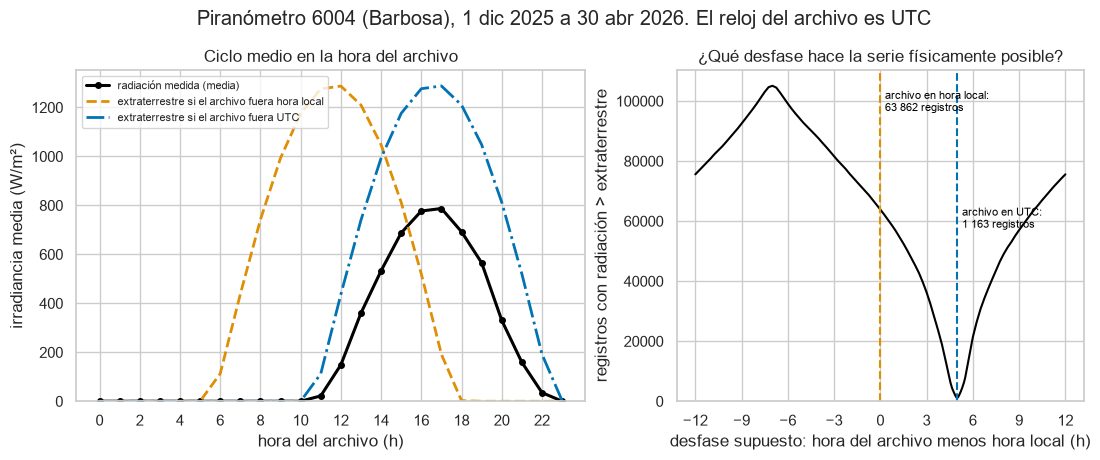

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
a1.plot(perfil.index, perfil["radiación medida"], color="black", lw=2.2, marker="o", ms=4, label="radiación medida (media)")
a1.plot(perfil.index, perfil["extraterrestre, archivo en hora local"], color=COL[1], ls="--", lw=2,
        label="extraterrestre si el archivo fuera hora local")
a1.plot(perfil.index, perfil["extraterrestre, archivo en UTC"], color=COL[0], ls="-.", lw=2,
        label="extraterrestre si el archivo fuera UTC")
a1.set(xlabel="hora del archivo (h)", ylabel="irradiancia media (W/m²)", xticks=range(0, 24, 2), ylim=(0, None),
       title="Ciclo medio en la hora del archivo")
a1.legend(loc="upper left", fontsize=8)
a2.plot(barrido.index / 60, barrido.values, color="black", lw=1.5)
for (nombre, desfase), c, y in zip(LECTURAS.items(), [COL[1], COL[0]], [0.92, 0.55]):
    a2.axvline(desfase / 60, color=c, ls="--", lw=1.5)
    a2.text(desfase / 60 + 0.3, barrido.max() * y, f"{nombre}:\n{miles(conteo[nombre])} registros", color="black", fontsize=8)
a2.set(xlabel="desfase supuesto: hora del archivo menos hora local (h)", ylabel="registros con radiación > extraterrestre",
       xticks=range(-12, 13, 3), ylim=(0, None), title="¿Qué desfase hace la serie físicamente posible?")
fig.suptitle(f"{SUB}. El reloj del archivo es UTC", y=1.02)
guardar(fig, "reloj_utc")
plt.show()

El archivo está en UTC. Leído como hora local, 63 862 registros superarían la radiación extraterrestre, que
solo se supera en minutos sueltos de realce por nubes; leído como UTC quedan 1 163. El pico medio de la radiación cae a
las 17 h del archivo, igual que la extraterrestre si el archivo es UTC; si fuera hora local, el pico de la extraterrestre
estaría a las 12 h. El barrido de desfases (derecha) tiene el mínimo en 299 min, a un minuto de 5 h exactas, y con 10 min
de error el conteo ya se duplica. Ese minuto de diferencia es del orden de la convención de la marca (si el promedio se
rotula al inicio o al final del minuto) y no se puede resolver con estos datos. Ni la ficha ni el archivo declaran la zona
horaria. Hay una segunda evidencia, independiente de la geometría, en A3: la regla del código 1582 solo cuadra en hora
local, después de restar las 5 h.

¿La conversión que hace `datos.regularizar` deja el ciclo donde debe estar?

In [7]:
hora_local = r.groupby(d.index.hour).mean()
print("pico del ciclo medio en hora local:", hora_local.idxmax(), "h;", hora_local.round(0).loc[6:18].to_dict())
print("primer minuto de la malla:", d.index[0], "| su marca en el archivo:", d["fecha_hora_archivo"].iloc[0])

pico del ciclo medio en hora local: 12 h; {6: 22.0, 7: 149.0, 8: 360.0, 9: 533.0, 10: 688.0, 11: 777.0, 12: 787.0, 13: 692.0, 14: 565.0, 15: 330.0, 16: 159.0, 17: 35.0, 18: 0.0}
primer minuto de la malla: 2025-11-30 19:00:00 | su marca en el archivo: 2025-12-01 00:00:00


`datos.regularizar` resta las 5 h (`utc_archivo = 0` en `ESTACIONES`). Con eso el pico medio queda a las
12 h locales (787 W/m²) y el primer minuto de la malla es el 30 nov 2025 a las 19:00 locales, que en el archivo es el
1 dic a las 00:00. Desde aquí todas las horas son locales.

## A2. Completitud temporal

¿Cuántos huecos hay, cuánto duran y cuánto pesa el más largo?

In [8]:
falta = ~d["presente"]
bloque = (falta != falta.shift()).cumsum()
g = d.index.to_series()[falta].groupby(bloque[falta])
huecos = pd.DataFrame({"inicio": g.first(), "fin": g.last(), "minutos": g.size()}).reset_index(drop=True)
huecos["clase"] = pd.cut(huecos["minutos"], [0, 1, 5, 60, np.inf], labels=["1 min", "2 a 5 min", "6 a 60 min", "más de 60 min"])
print(f"completitud: {d['presente'].mean():.2%} ({miles(int(d['presente'].sum()))} de {miles(len(d))} minutos)")
print(f"huecos: {len(huecos)}; minutos sin dato: {miles(int(falta.sum()))}; mediana {huecos['minutos'].median():.0f} min; "
      f"máximo {miles(int(huecos['minutos'].max()))} min")
display(huecos.groupby("clase", observed=False)["minutos"].agg(huecos="size", minutos="sum"))
largo = huecos.loc[huecos["minutos"].idxmax()]
print(f"hueco más largo: {largo['inicio']} a {largo['fin']} ({largo['minutos'] / 60:.1f} h), "
      f"el {largo['minutos'] / falta.sum():.0%} de los minutos sin dato")
huecos.sort_values("minutos", ascending=False).head(8)

completitud: 98.80% (214 823 de 217 440 minutos)
huecos: 207; minutos sin dato: 2 617; mediana 1 min; máximo 1 752 min


,huecos,minutos
clase,,
1 min,134,134
2 a 5 min,53,142
6 a 60 min,16,240
más de 60 min,4,2101


hueco más largo: 2026-04-08 05:41:00 a 2026-04-09 10:52:00 (29.2 h), el 67% de los minutos sin dato


,inicio,fin,minutos,clase
201,2026-04-08 05:41:00,2026-04-09 10:52:00,1752,más de 60 min
34,2025-12-23 08:19:00,2025-12-23 11:49:00,211,más de 60 min
15,2025-12-05 17:48:00,2025-12-05 18:59:00,72,más de 60 min
206,2026-04-28 08:08:00,2026-04-28 09:13:00,66,más de 60 min
169,2026-02-09 11:58:00,2026-02-09 12:42:00,45,6 a 60 min
36,2025-12-31 09:44:00,2025-12-31 10:19:00,36,6 a 60 min
8,2025-12-05 16:52:00,2025-12-05 17:21:00,30,6 a 60 min
2,2025-12-04 20:15:00,2025-12-04 20:39:00,25,6 a 60 min


La completitud es 98,80 % (214 823 de 217 440 minutos). Hay 207 huecos que suman 2 617 minutos, pero casi
todos son mínimos: 134 son de un solo minuto y la mediana es 1 min. Lo que pesa son cuatro huecos de más de una hora que
suman 2 101 minutos: el del 8 abr 05:41 al 9 abr 10:52 (1 752 min, 29,2 h, el 67 % de todo lo que falta), el del 23 dic
de 08:19 a 11:49 (211 min), el del 5 dic de 17:48 a 18:59 (72) y el del 28 abr de 08:08 a 09:13 (66).

¿Dónde caen los huecos en el calendario y en el día? El mapa muestra los minutos sin dato de cada hora; no se
rellena nada.

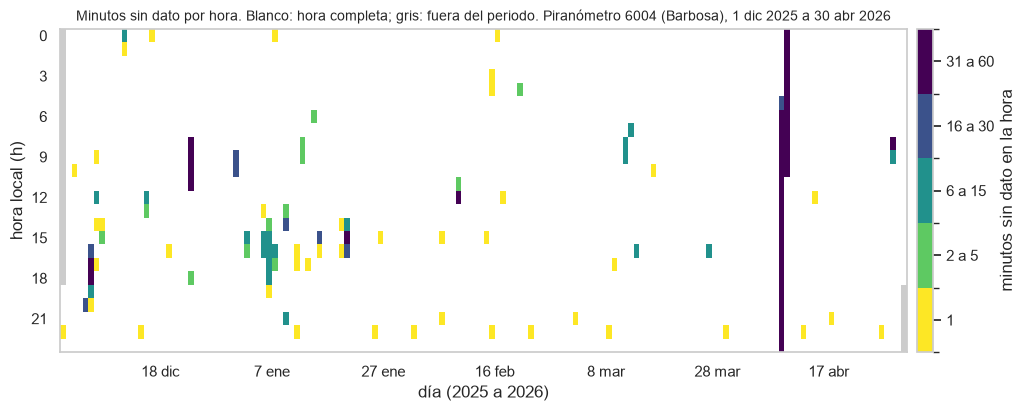

In [9]:
faltan = falta.astype(int).resample("h").sum()
mapa = (faltan.to_frame("n").assign(dia=faltan.index.normalize(), hora=faltan.index.hour)
        .pivot(index="hora", columns="dia", values="n"))
bordes_x = mdates.date2num(pd.date_range(mapa.columns[0], periods=mapa.shape[1] + 1, freq="D"))
cmap = plt.get_cmap("viridis_r").copy()
cmap.set_under("white")
cmap.set_bad("0.8")
norma = BoundaryNorm([0.5, 1.5, 5.5, 15.5, 30.5, 60.5], cmap.N)
fig, ax = plt.subplots(figsize=(13, 4.2))
pc = ax.pcolormesh(bordes_x, np.arange(25), np.ma.masked_invalid(mapa.to_numpy(float)), cmap=cmap, norm=norma)
cb = fig.colorbar(pc, ax=ax, ticks=[1, 3.5, 10.5, 23, 45.5], pad=0.01)
cb.ax.set_yticklabels(["1", "2 a 5", "6 a 15", "16 a 30", "31 a 60"])
cb.set_label("minutos sin dato en la hora")
ax.xaxis.set_major_formatter(FMT_FECHA)
ax.set(yticks=np.arange(0.5, 24, 3), yticklabels=range(0, 24, 3), ylabel="hora local (h)", xlabel="día (2025 a 2026)")
ax.invert_yaxis()
ax.set_title(f"Minutos sin dato por hora. Blanco: hora completa; gris: fuera del periodo. {SUB}", fontsize=10)
plt.show()

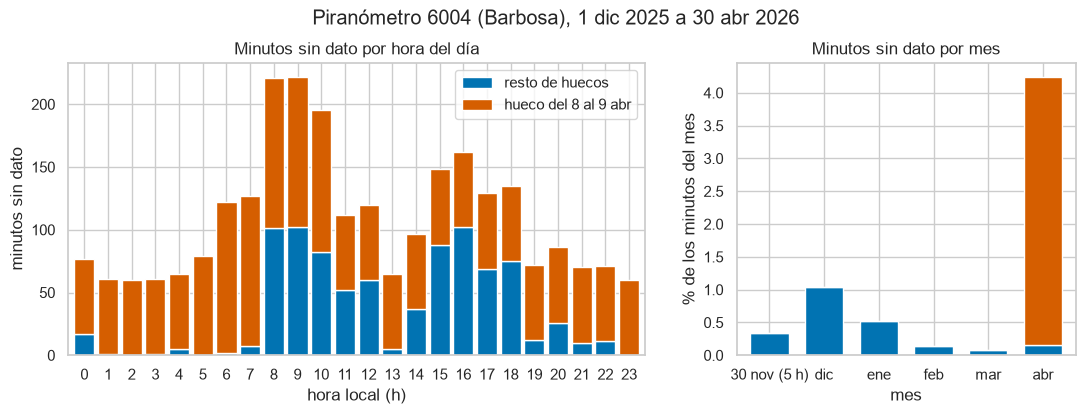

minutos sin dato por mes:
            resto de huecos  hueco del 8 al 9 abr
fecha_hora                                       
2025-11                   1                     0
2025-12                 465                     0
2026-01                 233                     0
2026-02                  59                     0
2026-03                  37                     0
2026-04                  70                  1752
% de los minutos del mes:
              resto de huecos  hueco del 8 al 9 abr  total
30 nov (5 h)             0.33                  0.00   0.33
dic                      1.04                  0.00   1.04
ene                      0.52                  0.00   0.52
feb                      0.15                  0.00   0.15
mar                      0.08                  0.00   0.08
abr                      0.16                  4.08   4.25


In [10]:
en_largo = (d.index >= largo["inicio"]) & (d.index <= largo["fin"])
mes = d.index.to_period("M")
por_hora = pd.DataFrame({"resto de huecos": (falta & ~en_largo).groupby(d.index.hour).sum(),
                         "hueco del 8 al 9 abr": (falta & en_largo).groupby(d.index.hour).sum()})
por_mes = pd.DataFrame({"resto de huecos": (falta & ~en_largo).groupby(mes).sum(),
                        "hueco del 8 al 9 abr": (falta & en_largo).groupby(mes).sum()})
por_mes_pct = 100 * por_mes.div(falta.groupby(mes).size(), axis=0)
por_mes_pct.index = ["30 nov (5 h)" if p.month == 11 else MESES[p.month] for p in por_mes_pct.index]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
por_hora.plot.bar(stacked=True, ax=a1, color=[COL[0], COL[3]], width=0.85, rot=0)
a1.set(xlabel="hora local (h)", ylabel="minutos sin dato", title="Minutos sin dato por hora del día")
por_mes_pct.plot.bar(stacked=True, ax=a2, color=[COL[0], COL[3]], width=0.7, rot=0, legend=False)
a2.set(xlabel="mes", ylabel="% de los minutos del mes", title="Minutos sin dato por mes")
fig.suptitle(SUB, y=1.02)
plt.show()
print("minutos sin dato por mes:")
print(por_mes.to_string())
print("% de los minutos del mes:")
print(por_mes_pct.round(2).assign(total=por_mes_pct.sum(axis=1).round(2)).to_string())

Sin el hueco del 8 al 9 de abril, los minutos sin dato se concentran de día: de 8 a 10 h (por los huecos
largos del 23 dic y el 28 abr) y de 15 a 18 h (por la racha de enero, siguiente celda, y por los cortes de la tarde del 5 dic). Por mes, diciembre pierde el
1,04 % de sus minutos, enero el 0,52 %, febrero el 0,15 %, marzo el 0,08 % y abril el 4,25 %, que sin el hueco largo
sería 0,16 %. Que los huecos caigan de día importa más que de noche: de noche la radiación es 0 y se sabe; de día se
pierde energía.

Los minutos cortos sin dato y las marcas tardías, ¿siguen algún patrón semanal o de fechas?

In [11]:
ventana = d.between_time("21:58", "22:05")
por_dia = ventana.groupby(ventana.index.normalize()).agg(sin_dato=("presente", lambda s: int((~s).sum())),
                                                         tardias=("fuera_de_minuto", "sum"))
por_dia["evento"] = (por_dia["sin_dato"] > 0) | (por_dia["tardias"] > 0)
evento = por_dia.groupby(por_dia.index.day_of_week)["evento"].agg(dias_con_evento="sum", dias="size")
evento.index = DIAS
print("minuto perdido o marca tardía entre las 21:58 y las 22:05 locales, por día de la semana:")
display(evento)
print("minuto exacto de esos huecos:", huecos.loc[huecos["inicio"].dt.time.astype(str).between("21:58:00", "22:05:00"),
                                                  "inicio"].dt.strftime("%H:%M").value_counts().to_dict())
cortos = huecos[huecos["minutos"] <= 2]
print("\nhuecos de 1 o 2 min por mes:", cortos.groupby(cortos["inicio"].dt.to_period("M")).size().to_dict())
ene = cortos[(cortos["inicio"] >= "2026-01-02") & (cortos["inicio"] < "2026-01-21")]
print(f"del 2 al 20 de enero: {len(ene)} huecos de 1 o 2 min; el {ene['inicio'].dt.hour.between(14, 17).mean():.0%} "
      f"empieza entre las 14 y las 17 h")

minuto perdido o marca tardía entre las 21:58 y las 22:05 locales, por día de la semana:


,dias_con_evento,dias
lunes,0,22
martes,0,22
miércoles,1,22
jueves,0,21
viernes,0,21
sábado,0,21
domingo,17,22


minuto exacto de esos huecos: {'22:01': 11}

huecos de 1 o 2 min por mes: {Period('2025-11', 'M'): 1, Period('2025-12', 'M'): 21, Period('2026-01', 'M'): 106, Period('2026-02', 'M'): 10, Period('2026-03', 'M'): 20, Period('2026-04', 'M'): 4}
del 2 al 20 de enero: 104 huecos de 1 o 2 min; el 76% empieza entre las 14 y las 17 h


Hay un evento semanal. 17 de los 22 domingos del periodo pierden el registro de las 22:01 locales o lo reciben
tarde (con segundos), frente a 1 de los 129 días restantes, y los 11 huecos de esa ventana son justo del minuto 22:01. Es
compatible con una tarea programada los domingos a las 22 h, por ejemplo una sincronización del reloj o un reinicio
(inferido; no hay bitácora para confirmarlo). Aparte, del 2 al 20 de enero hubo 104 cortes de 1 o 2 minutos, el 76 %
entre las 14 y las 17 h: una falla de comunicación intermitente en las tardes de esas semanas (inferido).

¿Cómo se ve la serie minutal alrededor del hueco más largo? La línea se corta donde no hay dato.

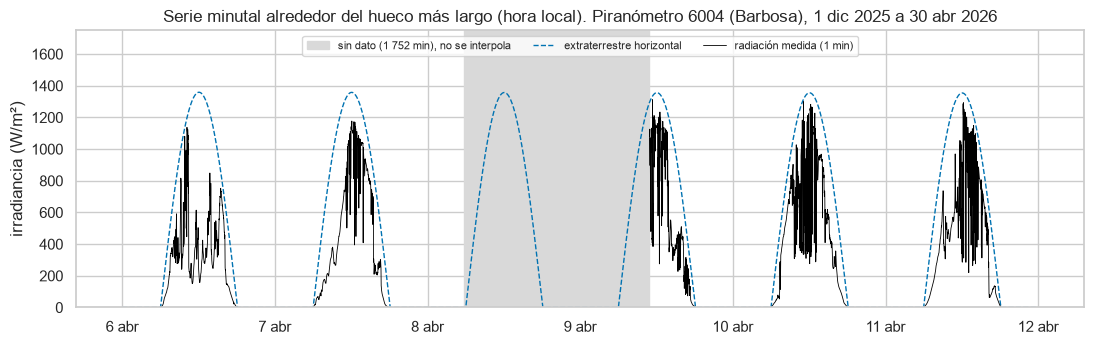

In [12]:
tramo = d.loc[largo["inicio"].normalize() - pd.Timedelta("2D"): largo["fin"].normalize() + pd.Timedelta("2D23h59min")]
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.axvspan(largo["inicio"], largo["fin"], color="0.85", label=f"sin dato ({miles(int(largo['minutos']))} min), no se interpola")
ax.plot(tramo.index, tramo["et"], color=COL[0], ls="--", lw=1, label="extraterrestre horizontal")
ax.plot(tramo.index, tramo["radiacion"], color="black", lw=0.6, label="radiación medida (1 min)")
ax.set(ylabel="irradiancia (W/m²)", ylim=(0, 1750), title=f"Serie minutal alrededor del hueco más largo (hora local). {SUB}")
ax.xaxis.set_major_formatter(FMT_FECHA)
ax.legend(loc="upper center", fontsize=8, ncol=3)
plt.show()

El hueco empieza a las 05:41 del 8 abr, antes del amanecer, y termina a las 10:52 del 9 abr: se pierde un día
entero de sol y la mañana del siguiente. El primer valor al volver (1075,95 W/m²) es el que llegó con la marca 15:53:20
del archivo. No se rellena nada: el 8 abr queda sin energía diaria y el 9 abr también, porque solo tiene el 60 % de sus
minutos con sol.

## A3. Distribución de la radiación y de la columna calidad

Se calcula primero la energía diaria (kWh/m² por día) porque se usa aquí y en A4. Un día solo cuenta si tiene al menos
el 99 % de los minutos con el sol sobre el horizonte; los demás quedan vacíos (no se rellenan). La noche no aporta
energía, así que sus huecos no la sesgan.

In [13]:
dia = d.index.normalize()
de_dia = (d["elevacion"] > 0).to_numpy()
diario = pd.DataFrame({
    "E": r.groupby(dia).sum(min_count=1) / 60 / 1000,      # W/m² por minuto -> kWh/m²
    "ET": d["et"].groupby(dia).sum() / 60 / 1000,
    "cobertura_diurna": d.loc[de_dia, "presente"].groupby(dia[de_dia]).mean(),
}).loc["2025-12-01":]
diario["E"] = diario["E"].where(diario["cobertura_diurna"] >= 0.99)
diario["KT"] = diario["E"] / diario["ET"]
print(f"días: {len(diario)}; con energía válida: {int(diario['E'].notna().sum())}")
print("días excluidos:", [f"{t.day} {MESES[t.month]} ({c:.0%})" for t, c in diario.loc[diario["E"].isna(), "cobertura_diurna"].items()])
diario[["E", "ET", "KT"]].describe().round(2).T

días: 151; con energía válida: 134
días excluidos: ['5 dic (91%)', '6 dic (98%)', '15 dic (99%)', '23 dic (70%)', '31 dic (95%)', '2 ene (98%)', '5 ene (97%)', '6 ene (94%)', '7 ene (98%)', '9 ene (97%)', '15 ene (98%)', '20 ene (90%)', '9 feb (94%)', '11 mar (98%)', '8 abr (0%)', '9 abr (60%)', '28 abr (91%)']


,count,mean,std,min,25%,50%,75%,max
E,134.0,5.15,1.38,1.41,4.23,5.21,6.21,7.52
ET,151.0,9.81,0.54,9.07,9.19,9.90,10.37,10.45
KT,134.0,0.52,0.13,0.14,0.44,0.54,0.63,0.74


¿Cómo se distribuye la radiación de día y qué tan claro suele estar el cielo? El índice de claridad
kt = radiación / extraterrestre horizontal separa el efecto de la geometría solar del de las nubes (se usa con el sol a
más de 5°, donde la extraterrestre no es casi cero).

minutos con el sol a más de 3° bajo el horizonte: 105 468; con radiación exactamente 0: 100.00%


radiación con el sol arriba, percentiles (W/m²): {0.05: 11.0, 0.25: 110.0, 0.5: 345.0, 0.75: 715.0, 0.95: 1072.0, 0.99: 1194.0}
kt, percentiles: {0.05: 0.092, 0.25: 0.234, 0.5: 0.406, 0.75: 0.74, 0.95: 0.858}
kt < 0,3: 36.0%; kt > 0,7: 28.9%; kt > 1: 537 minutos
modas del kt: [np.float64(0.788), np.float64(0.812), np.float64(0.238), np.float64(0.262), np.float64(0.213), np.float64(0.288)]


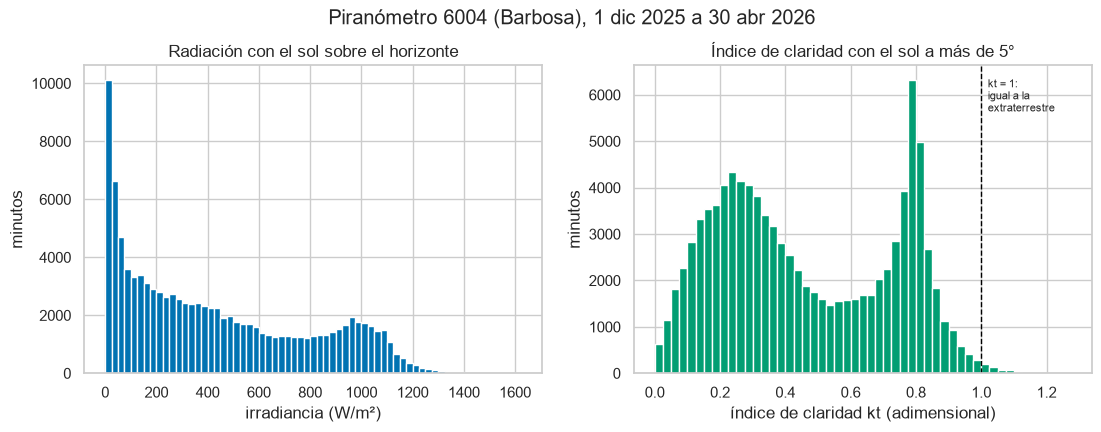

In [14]:
noche = d["elevacion"] < -3
print(f"minutos con el sol a más de 3° bajo el horizonte: {miles(int((noche & r.notna()).sum()))}; "
      f"con radiación exactamente 0: {(r[noche].dropna() == 0).mean():.2%}")
dia_sol = (d["elevacion"] > 0) & r.notna()
print("radiación con el sol arriba, percentiles (W/m²):", r[dia_sol].quantile([0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(0).to_dict())
kt = (r / d["et"]).where(d["elevacion"] > 5)
print("kt, percentiles:", kt.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).to_dict())
print(f"kt < 0,3: {(kt < 0.3).sum() / kt.notna().sum():.1%}; kt > 0,7: {(kt > 0.7).sum() / kt.notna().sum():.1%}; "
      f"kt > 1: {int((kt > 1).sum())} minutos")
conteo_kt, bordes_kt = np.histogram(kt.dropna(), bins=np.arange(0, 1.3, 0.025))
print("modas del kt:", [round(bordes_kt[i] + 0.0125, 3) for i in np.argsort(conteo_kt)[::-1][:6]])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.hist(r[dia_sol], bins=np.arange(0, 1650, 25), color=COL[0])
a1.set(xlabel="irradiancia (W/m²)", ylabel="minutos", title="Radiación con el sol sobre el horizonte")
a2.hist(kt.dropna(), bins=bordes_kt, color=COL[2])
a2.axvline(1, color="black", ls="--", lw=1)
a2.text(1.02, a2.get_ylim()[1] * 0.85, "kt = 1:\nigual a la\nextraterrestre", fontsize=8)
a2.set(xlabel="índice de claridad kt (adimensional)", ylabel="minutos", title="Índice de claridad con el sol a más de 5°")
fig.suptitle(SUB, y=1.02)
plt.show()

De noche (sol a más de 3° bajo el horizonte) los 105 468 minutos valen 0,00 exacto, el 100 %. Con el sol
arriba la distribución es asimétrica: mediana de 345 W/m², percentil 95 de 1072 y percentil 99 de 1194 W/m², con muchos
minutos bajos por el amanecer, el atardecer y las nubes. El índice de claridad es bimodal: un modo cerca de 0,24 (cielo
cubierto; el 36,0 % de los minutos tiene kt < 0,3) y otro cerca de 0,79 (cielo despejado; el 28,9 % tiene kt > 0,7).
Hay 537 minutos con kt > 1, es decir, sobre la extraterrestre; se analizan en A5.

¿Cómo cambia la distribución con la hora del día y con el mes?

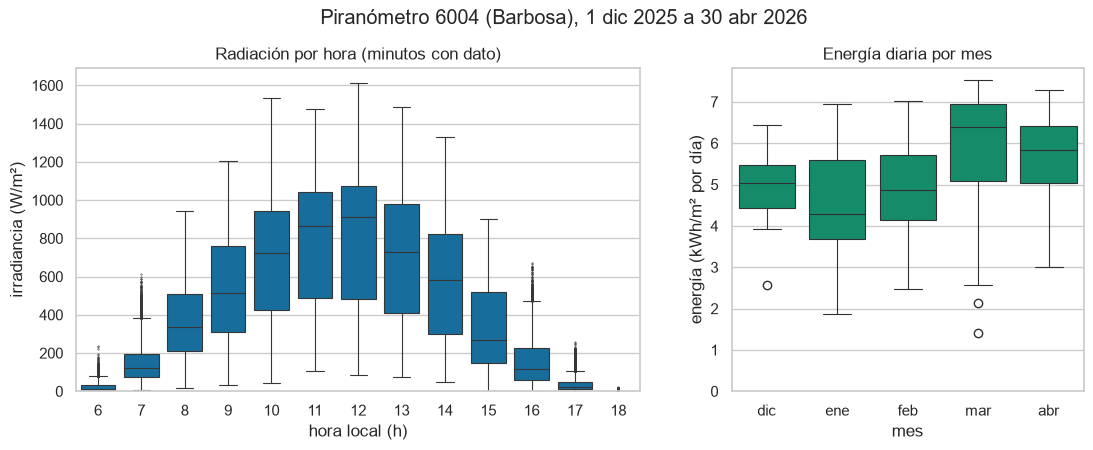

hora     6      7      8       9       10      11      12      13      14     15     16     17    18
50%    13.0  120.0  336.0   515.0   722.0   863.0   912.0   731.0   580.0  270.0  118.0   25.0   0.0
75%    33.0  196.0  508.0   757.0   942.0  1042.0  1074.0   980.0   821.0  521.0  225.0   48.0   0.0
max   234.0  611.0  942.0  1202.0  1535.0  1479.0  1611.0  1489.0  1329.0  902.0  670.0  258.0  20.0
     count  mean   50%   min   max
mes                               
abr   27.0  5.62  5.83  3.01  7.30
dic   26.0  5.00  5.03  2.57  6.45
ene   24.0  4.46  4.28  1.87  6.94
feb   27.0  4.75  4.86  2.46  7.01
mar   30.0  5.75  6.40  1.41  7.52


In [15]:
horas = d.loc[d.index.hour.isin(range(6, 19)) & r.notna(), ["radiacion"]].assign(hora=lambda t: t.index.hour)
e_mes = diario.dropna(subset=["E"]).assign(mes=lambda t: t.index.month.map(MESES))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
sns.boxplot(data=horas, x="hora", y="radiacion", ax=a1, color=COL[0], fliersize=0.4, linewidth=0.8)
a1.set(xlabel="hora local (h)", ylabel="irradiancia (W/m²)", ylim=(0, None), title="Radiación por hora (minutos con dato)")
sns.boxplot(data=e_mes, x="mes", y="E", order=["dic", "ene", "feb", "mar", "abr"], ax=a2, color=COL[2], linewidth=0.8)
a2.set(xlabel="mes", ylabel="energía (kWh/m² por día)", ylim=(0, None), title="Energía diaria por mes")
fig.suptitle(SUB, y=1.02)
plt.show()
print(horas.groupby("hora")["radiacion"].describe()[["50%", "75%", "max"]].round(0).T.to_string())
print(e_mes.groupby("mes")["E"].describe()[["count", "mean", "50%", "min", "max"]].round(2).to_string())

Por hora, la mediana sube hasta 912 W/m² a las 12 h y 863 a las 11 h, y los máximos de 10 a 13 h pasan de
1400 W/m² (realce por nubes, A5). Por mes, la energía diaria mediana es 5,03 kWh/m² en diciembre, 4,28 en enero, 4,86 en
febrero, 6,40 en marzo y 5,83 en abril. Enero tiene la mayor dispersión hacia abajo (mínimo 1,87) y marzo tiene como
atípico el día más bajo del periodo (1,41 kWh/m², 8 mar).

### Columna calidad

¿Qué códigos aparecen, con qué valores y a qué horas? Solo hay 1, 1582 y 1583: no aparecen 151 ni 1581.

In [16]:
c = d.dropna(subset=["calidad"]).assign(calidad=lambda t: t["calidad"].astype(int), hora=lambda t: t.index.hour)
resumen = c.groupby("calidad").agg(minutos=("radiacion", "size"), rad_mediana=("radiacion", "median"),
                                   rad_p95=("radiacion", lambda s: s.quantile(0.95)), rad_max=("radiacion", "max"),
                                   elev_mediana=("elevacion", "median"),
                                   sol_arriba=("elevacion", lambda s: (s > 0).mean()))
resumen["horas_locales"] = c.groupby("calidad")["hora"].agg(lambda s: sorted(s.unique()))
resumen.round(2)

,minutos,rad_mediana,rad_p95,rad_max,elev_mediana,sol_arriba,horas_locales
calidad,,,,,,,
1,213093,0.00,983.22,1360.38,-2.13,0.49,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
1582,977,2.73,11.51,20.50,0.86,0.79,"[5, 6, 18]"
1583,753,1153.80,1401.64,1611.03,54.85,0.99,"[6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]"


El 1582 dice "mayor a 0 de noche". ¿Es de noche cuando aparece? Se compara con la elevación solar y con una
regla de reloj fija (de 18:00 a 06:00 locales).

In [17]:
es1582 = d["calidad"] == 1582
q82 = d[es1582]
print(f"1582: {len(q82)} minutos; con el sol sobre el horizonte: {(q82['elevacion'] > 0).mean():.1%}; "
      f"elevación mediana {q82['elevacion'].median():.2f}°; radiación mediana {q82['radiacion'].median():.2f} W/m², "
      f"máxima {q82['radiacion'].max():.1f}")
minuto_dia = d.index.hour * 60 + d.index.minute
regla_local = ((minuto_dia >= 18 * 60) | (minuto_dia <= 6 * 60)) & (r > 0)
archivo = d.index + pd.Timedelta(hours=5)
minuto_archivo = archivo.hour * 60 + archivo.minute
regla_archivo = ((minuto_archivo >= 18 * 60) | (minuto_archivo <= 6 * 60)) & (r > 0)
display(pd.crosstab(regla_local, es1582, rownames=["r > 0 entre 18:00 y 06:00 locales"], colnames=["calidad = 1582"]))
display(pd.crosstab(regla_archivo, es1582, rownames=["r > 0 entre 18:00 y 06:00 del archivo"], colnames=["calidad = 1582"]))
arriba = (d["elevacion"] > 0).to_numpy()
t_arriba = d.index.to_series()[arriba]
salida = t_arriba.groupby(t_arriba.index.normalize()).min()
puesta = t_arriba.groupby(t_arriba.index.normalize()).max()
hm = lambda s: s.dt.strftime("%H:%M")
print("salida del sol calculada:", hm(salida).min(), "a", hm(salida).max(), "| puesta:", hm(puesta).min(), "a", hm(puesta).max())
cruce = puesta[puesta.dt.hour * 60 + puesta.dt.minute >= 18 * 60].index.min()
print("primer día con la puesta del sol a las 18:00 o después:", fecha(cruce))
print("elevación media del sol a las 18:00 locales por mes:",
      d.at_time("18:00").groupby(d.at_time("18:00").index.month)["elevacion"].mean().round(2).rename(MESES).to_dict())

1582: 977 minutos; con el sol sobre el horizonte: 78.9%; elevación mediana 0.86°; radiación mediana 2.73 W/m², máxima 20.5


calidad = 1582,False,True
r > 0 entre 18:00 y 06:00 locales,,
False,216463,0
True,0,977


calidad = 1582,False,True
r > 0 entre 18:00 y 06:00 del archivo,,
False,172324,145
True,44139,832


salida del sol calculada: 05:53 a 06:23 | puesta: 17:40 a 18:11
primer día con la puesta del sol a las 18:00 o después: 14 ene 2026
elevación media del sol a las 18:00 locales por mes: {'ene': 0.17, 'feb': 2.33, 'mar': 2.45, 'abr': 1.55, 'dic': -3.07}


El 1582 no se asigna por la posición del sol sino por el reloj. La regla "radiación > 0 entre las 18:00 y
las 06:00 locales" reproduce los 977 minutos con 1582 sin un solo desacuerdo. Por eso el 78,9 % de esos minutos tiene el
sol sobre el horizonte (elevación mediana 0,86°) y su radiación es la del crepúsculo (mediana 2,73 W/m², máximo 20,5).
La puesta del sol calculada va de las 17:40 a las 18:11 en el periodo y desde el 14 ene ocurre a las 18:00 o después: de
ahí en adelante cada atardecer con luz después de las 18:00 sale como dudoso. La misma regla aplicada al reloj del
archivo no cuadra (44 139 minutos la cumplirían sin tener 1582): otra evidencia de que el archivo está en UTC y de que
SIATA calcula el código en hora local antes de exportar.

El 1583 dice "supera la radiación teórica". ¿Coincide con superar la extraterrestre horizontal?

In [18]:
q83 = d[d["calidad"] == 1583].assign(cociente=lambda t: (t["radiacion"] / t["et"]).replace(np.inf, np.nan),
                                     hora=lambda t: t.index.hour)
display(q83.groupby("hora").agg(minutos=("radiacion", "size"), rad_mediana=("radiacion", "median"),
                                et_mediana=("et", "median"), cociente_mediano=("cociente", "median")).round(2).T)
sobre_et = (r > d["et"]) & (d["elevacion"] > 0)
print(f"1583 con radiación <= extraterrestre: {int((q83['radiacion'] <= q83['et']).sum())} de {len(q83)} "
      f"({(q83['radiacion'] <= q83['et']).mean():.0%}); con extraterrestre 0: {int((q83['et'] == 0).sum())}")
print(f"minutos sobre la extraterrestre con el sol arriba: {int(sobre_et.sum())}; con 1583: "
      f"{int((sobre_et & (d['calidad'] == 1583)).sum())}; con 1: {int((sobre_et & (d['calidad'] == 1)).sum())}; "
      f"con 1582: {int((sobre_et & es1582).sum())}")
print("minuto de los 1583 de las 06 h y de las 17 h:",
      q83[q83["hora"].isin([6, 17])].index.strftime("%H:%M").value_counts().head(8).to_dict())

hora,6,8,9,10,11,12,13,14,15,16,17
minutos,28.00,1.00,21.00,42.00,99.00,125.00,97.00,97.00,34.00,16.00,193.00
rad_mediana,5.03,882.07,1093.30,1260.88,1343.12,1332.40,1286.52,1062.47,770.03,631.72,16.20
et_mediana,19.38,779.71,1038.95,1185.88,1253.45,1271.49,1234.15,1064.73,770.28,653.89,90.70
cociente_mediano,0.19,1.13,1.04,1.06,1.05,1.04,1.04,1.02,0.97,0.94,0.21


1583 con radiación <= extraterrestre: 308 de 753 (41%); con extraterrestre 0: 9
minutos sobre la extraterrestre con el sol arriba: 612; con 1583: 436; con 1: 138; con 1582: 38
minuto de los 1583 de las 06 h y de las 17 h: {'17:49': 33, '06:11': 24, '17:50': 19, '17:51': 18, '17:52': 16, '17:53': 15, '17:54': 14, '17:56': 13}


¿Cómo se ven juntas las dos reglas de SIATA frente a la geometría solar?

guardada 03_codigos_calidad.png (103 KB)


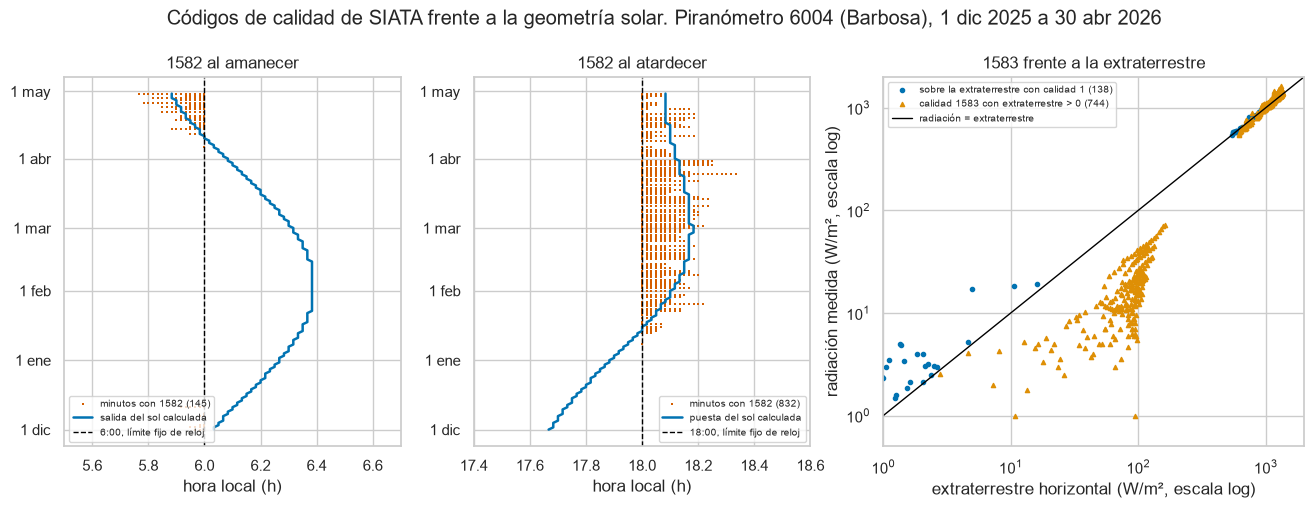

In [19]:
hora_dec = lambda ix: ix.hour + ix.minute / 60
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for a, (h0, h1), limite, linea, nombre in [(ax[0], (5.5, 6.7), 6, salida, "salida del sol"),
                                           (ax[1], (17.4, 18.6), 18, puesta, "puesta del sol")]:
    sel = q82[(hora_dec(q82.index) >= h0) & (hora_dec(q82.index) <= h1)]
    a.scatter(hora_dec(sel.index), sel.index.normalize(), s=4, color=COL[3], marker="s", linewidths=0, label=f"minutos con 1582 ({len(sel)})")
    a.plot(linea.dt.hour + linea.dt.minute / 60, linea.index, color=COL[0], lw=1.8, label=f"{nombre} calculada")
    a.axvline(limite, color="black", ls="--", lw=1, label=f"{limite}:00, límite fijo de reloj")
    a.set(xlim=(h0, h1), xlabel="hora local (h)", title=f"1582 al {'amanecer' if limite == 6 else 'atardecer'}")
    a.yaxis.set_major_formatter(FMT_FECHA)
    a.legend(fontsize=7, loc="lower left" if limite == 6 else "lower right")
p83 = q83[q83["et"] > 0]
p1 = d[sobre_et & (d["calidad"] == 1)]
ax[2].scatter(p1["et"], p1["radiacion"], s=9, color=COL[0], marker="o", label=f"sobre la extraterrestre con calidad 1 ({len(p1)})")
ax[2].scatter(p83["et"], p83["radiacion"], s=9, color=COL[1], marker="^", label=f"calidad 1583 con extraterrestre > 0 ({len(p83)})")
ax[2].plot([0.5, 2000], [0.5, 2000], color="black", lw=1, label="radiación = extraterrestre")
ax[2].set(xscale="log", yscale="log", xlim=(1, 2000), ylim=(0.5, 2000), xlabel="extraterrestre horizontal (W/m², escala log)",
          ylabel="radiación medida (W/m², escala log)", title="1583 frente a la extraterrestre")
ax[2].legend(fontsize=7, loc="upper left")
fig.suptitle(f"Códigos de calidad de SIATA frente a la geometría solar. {SUB}", y=1.02)
guardar(fig, "codigos_calidad")
plt.show()

El 1583 se parece a "supera la extraterrestre" solo cerca del mediodía. De 8 a 14 h el cociente mediano
radiación / extraterrestre de los minutos con 1583 está entre 1,02 y 1,13. Pero 308 de los 753 minutos con 1583 (41 %)
están por debajo de la extraterrestre: a las 15 y 16 h el cociente es 0,97 y 0,94, y a las 6 y 17 h cae a 0,19 y 0,21,
con radiaciones medianas de 5 y 16 W/m²; 9 tienen extraterrestre 0. Esos minutos del amanecer y el atardecer se repiten
en minutos fijos del reloj (06:11 en 24 casos, 17:49 en 33), lo que sugiere que la radiación teórica de SIATA no sigue la
geometría solar de cada día (inferido; el modelo no está publicado). Al revés, de los 612 minutos que sí superan la
extraterrestre con el sol arriba, 138 salen con calidad 1 y 38 con 1582. En la figura de la derecha, los triángulos bajo
la diagonal son 1583 que no superan nada y los círculos sobre ella son excesos que pasaron como confiables.

¿Los códigos cambian a lo largo del periodo?

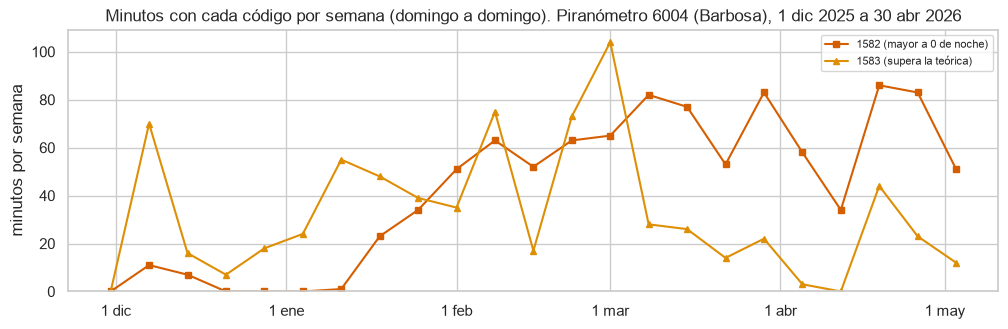

fecha_hora  nov  dic  ene  feb  mar  abr
1582          0   18  103  237  338  281
1583          0  117  193  265   97   81


In [20]:
semanal = pd.DataFrame({"1582": (d["calidad"] == 1582).resample("W-SUN").sum(),
                        "1583": (d["calidad"] == 1583).resample("W-SUN").sum()})
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(semanal.index, semanal["1582"], marker="s", ms=4, color=COL[3], label="1582 (mayor a 0 de noche)")
ax.plot(semanal.index, semanal["1583"], marker="^", ms=4, color=COL[1], label="1583 (supera la teórica)")
ax.set(ylabel="minutos por semana", ylim=(0, None), title=f"Minutos con cada código por semana (domingo a domingo). {SUB}")
ax.xaxis.set_major_formatter(FMT_FECHA)
ax.legend(fontsize=8)
plt.show()
mensual = pd.DataFrame({k: (d["calidad"] == int(k)).groupby(d.index.month).sum() for k in ["1582", "1583"]}).rename(index=MESES).reindex(["nov", "dic", "ene", "feb", "mar", "abr"])
print(mensual.T.to_string())

Los cambios de los dos códigos tienen causa astronómica. El 1582 casi no aparece en diciembre (18
minutos) y sube a 237 en febrero y 338 en marzo, a medida que la puesta del sol pasa de las 18:00. El 1583 es mayor en
enero y febrero (193 y 265) y baja en marzo y abril (97 y 81), sobre todo por los minutos de 8 a 14 h y en parte por los de las 17 h. Quien use la columna para
seguir la calidad del sensor en el tiempo vería un deterioro de enero a marzo que no existe.

## A4. Ciclos, estacionalidad y tendencia

¿Cómo es el ciclo diurno en hora local y cambia de un mes a otro?

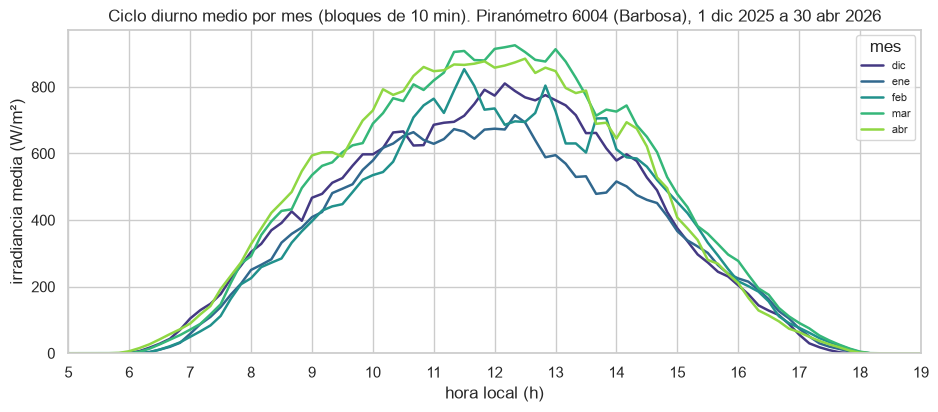

hora local con la media más alta por mes: {'dic': 12.166666666666666, 'ene': 12.333333333333334, 'feb': 11.5, 'mar': 12.333333333333334, 'abr': 12.5}
media por hora local (W/m²): {6: 22.0, 7: 149.0, 8: 360.0, 9: 533.0, 10: 688.0, 11: 777.0, 12: 787.0, 13: 692.0, 14: 565.0, 15: 330.0, 16: 159.0, 17: 35.0, 18: 0.0}


In [21]:
bin10 = (d.index.hour * 60 + d.index.minute) // 10 * 10 / 60
ciclo = r.groupby([d.index.month, bin10]).mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4.2))
for color, m in zip(sns.color_palette("viridis", 5), [12, 1, 2, 3, 4]):
    ax.plot(ciclo.index, ciclo[m], color=color, lw=1.8, label=MESES[m])
ax.set(xlim=(5, 19), xticks=range(5, 20), ylim=(0, None), xlabel="hora local (h)", ylabel="irradiancia media (W/m²)",
       title=f"Ciclo diurno medio por mes (bloques de 10 min). {SUB}")
ax.legend(title="mes", fontsize=8)
plt.show()
print("hora local con la media más alta por mes:", {MESES[m]: float(ciclo[m].idxmax()) for m in [12, 1, 2, 3, 4]})
print("media por hora local (W/m²):", hora_local.round(0).loc[6:18].to_dict())

En hora local el ciclo es casi simétrico alrededor del mediodía, con la media más alta entre las 11:30 y las
12:40 según el mes (787 W/m² en la hora de las 12). La ficha técnica de la estación (2017 a 2022, solo calidad 1) también
muestra el pico a las 11 y 12 h locales, lo que respalda la conversión. Marzo y abril tienen el ciclo más alto y enero el
más bajo, sobre todo de 13 a 15 h, lo que coincide con su índice de claridad más bajo (gráfico de energía).

¿Hay ciclo semanal? Físicamente no debería haberlo.

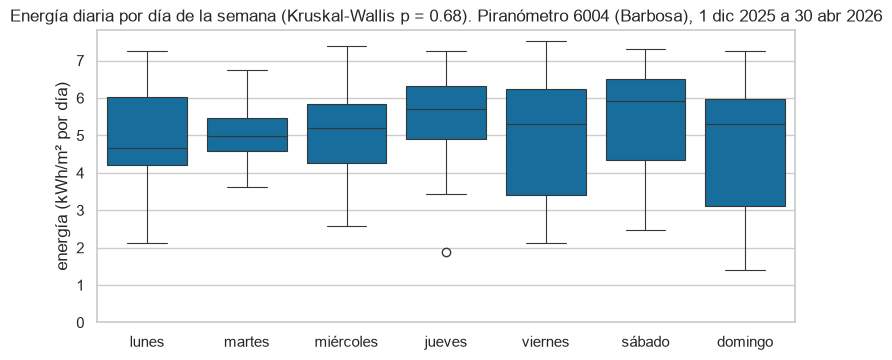

        lunes  martes  miércoles  jueves  viernes  sábado  domingo
count   19.00   18.00      18.00   20.00    18.00   20.00    21.00
mean     5.01    5.05       5.06    5.41     5.05    5.57     4.86
median   4.65    4.98       5.19    5.70     5.31    5.91     5.30
Kruskal-Wallis: H = 3.98, p = 0.68


In [22]:
e = diario.dropna(subset=["E"]).assign(dia_semana=lambda t: t.index.day_of_week)
kw = stats.kruskal(*[g["E"] for _, g in e.groupby("dia_semana")])
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=e, x="dia_semana", y="E", ax=ax, color=COL[0], linewidth=0.8)
ax.set_xticks(range(7), DIAS)
ax.set(xlabel="", ylabel="energía (kWh/m² por día)", ylim=(0, None),
       title=f"Energía diaria por día de la semana (Kruskal-Wallis p = {kw.pvalue:.2f}). {SUB}")
plt.show()
print(e.groupby("dia_semana")["E"].agg(["count", "mean", "median"]).round(2).set_axis(DIAS).T.to_string())
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.2f}")

No hay ciclo semanal. Las medias por día de la semana van de 4,86 a 5,57 kWh/m² y la prueba de Kruskal-Wallis
no encuentra diferencia (H = 3,98; p = 0,68). Es lo esperado. El único rastro semanal de esta estación está en los huecos del domingo a las 22:01 (A2),
que vienen del sistema de adquisición.

¿Cómo evoluciona la energía diaria de diciembre a abril y cuánto de ese cambio es astronómico? La energía
medida es el producto de la extraterrestre diaria (geometría solar, fija y conocida) por el índice de claridad diario
KT (nubes y atmósfera). Esa es la descomposición sencilla que tiene sentido físico aquí; un STL con periodo semanal no
aporta porque no hay ciclo semanal.

guardada 03_energia_diaria.png (83 KB)

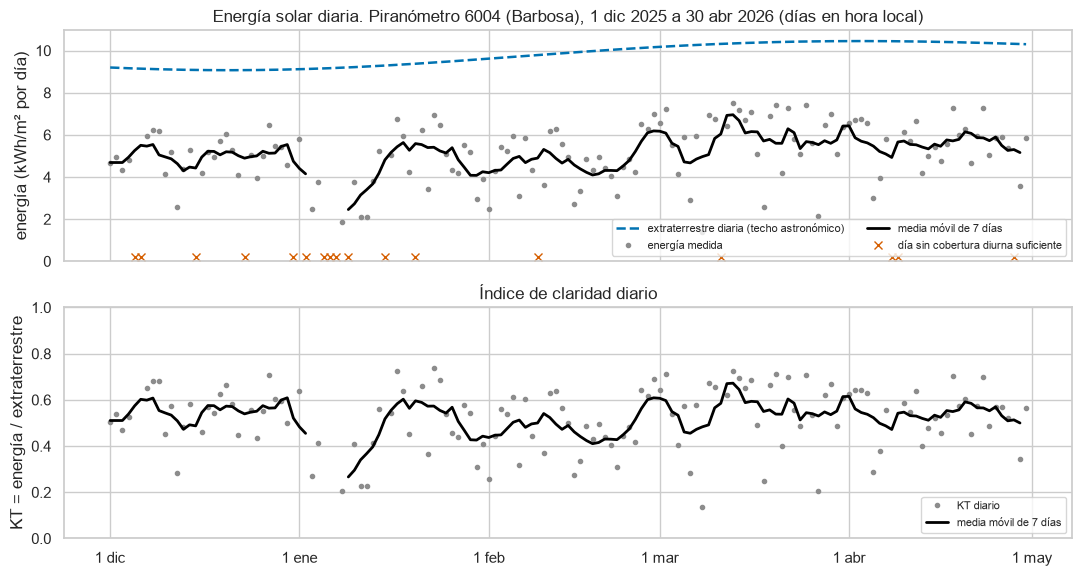

fecha_hora    dic    ene    feb     mar     abr
E           4.999  4.464  4.753   5.752   5.624
ET          9.104  9.325  9.900  10.351  10.403
KT          0.549  0.476  0.480   0.556   0.541
tendencia lineal de E: +0.263 por mes (p = 0.00143)
tendencia lineal de ET: +0.355 por mes (p = 1.02e-71)
tendencia lineal de KT: +0.007 por mes (p = 0.359)
la extraterrestre diaria de abril supera a la de diciembre en 14.3%
día de más energía: 13 mar 2026 (7.52); de menos: 8 mar 2026 (1.41)


In [23]:
movil = lambda s: s.rolling(7, center=True, min_periods=4).mean()
excluidos = diario.index[diario["E"].isna()]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True)
a1.plot(diario.index, diario["ET"], color=COL[0], ls="--", lw=1.8, label="extraterrestre diaria (techo astronómico)")
a1.plot(diario.index, diario["E"], "o", ms=3, color="0.55", label="energía medida")
a1.plot(diario.index, movil(diario["E"]), color="black", lw=2, label="media móvil de 7 días")
a1.plot(excluidos, np.zeros(len(excluidos)) + 0.2, "x", color=COL[3], ms=6, label="día sin cobertura diurna suficiente")
a1.set(ylabel="energía (kWh/m² por día)", ylim=(0, None), title=f"Energía solar diaria. {SUB} (días en hora local)")
a1.legend(fontsize=8, ncol=2, loc="lower right")
a2.plot(diario.index, diario["KT"], "o", ms=3, color="0.55", label="KT diario")
a2.plot(diario.index, movil(diario["KT"]), color="black", lw=2, label="media móvil de 7 días")
a2.set(ylabel="KT = energía / extraterrestre", ylim=(0, 1), title="Índice de claridad diario")
a2.legend(fontsize=8, loc="lower right")
a2.xaxis.set_major_formatter(FMT_FECHA)
guardar(fig, "energia_diaria")
plt.show()
mes_tab = diario.groupby(diario.index.month)[["E", "ET", "KT"]].mean().rename(index=MESES).loc[["dic", "ene", "feb", "mar", "abr"]]
print(mes_tab.round(3).T.to_string())
t = diario.dropna(subset=["KT"])
x = (t.index - t.index[0]).days
for col in ["E", "ET", "KT"]:
    lr = stats.linregress(x, t[col])
    print(f"tendencia lineal de {col}: {lr.slope * 30:+.3f} por mes (p = {lr.pvalue:.3g})")
print(f"la extraterrestre diaria de abril supera a la de diciembre en {mes_tab.loc['abr', 'ET'] / mes_tab.loc['dic', 'ET'] - 1:.1%}")
print(f"día de más energía: {fecha(diario['E'].idxmax())} ({diario['E'].max():.2f}); de menos: {fecha(diario['E'].idxmin())} ({diario['E'].min():.2f})")

La energía media es 5,15 kWh/m² por día (134 días válidos) y sube de diciembre a abril: 5,00; 4,46; 4,75;
5,75 y 5,62 kWh/m² por día en promedio mensual. La tendencia lineal es de +0,263 kWh/m² por mes (p = 0,001), pero la
explica la geometría: la extraterrestre diaria de abril es 14,3 % mayor que la de diciembre (+0,355 por mes), porque en
abril el sol del mediodía pasa casi por el cenit de Barbosa (6,4° N). El índice de claridad no tiene tendencia (+0,007
por mes, p = 0,36): baja de 0,55 en diciembre a 0,48 en enero y febrero y vuelve a 0,56 y 0,54 en marzo y abril. Los
p valores suponen días independientes, que no lo son, así que son orientativos. El día de más energía fue el 13 mar
(7,52 kWh/m²) y el de menos el 8 mar (1,41). Los 17 días sin cobertura suficiente quedan como huecos (cruces), no se
rellenan.

## A5. Consistencia física e interna

Hay una sola variable, así que la consistencia interna es entre `radiacion` y `calidad`, y la física es frente a la
geometría solar.

¿Cuántos minutos violan los límites de BSRN para radiación global? Los límites se toman de Long y Dutton
(BSRN, recomendaciones de control de calidad V2.0; Long y Shi, 2008, recogen todos menos el máximo extremadamente raro): físicamente posible
Sa·1,5·μ^1,2 + 100 y mínimo -4 W/m²; extremadamente raro Sa·1,2·μ^1,2 + 50 y mínimo -2 W/m², con μ el coseno del
ángulo cenital y Sa la constante solar corregida por distancia. Los calcula `calidad.limites_bsrn`.

In [24]:
posible, raro = Q.limites_bsrn(d)
sol_arriba = d["elevacion"] > 0
cuenta = pd.Series({
    "minutos con dato y el sol arriba": int((sol_arriba & r.notna()).sum()),
    "sobre la extraterrestre horizontal": int(sobre_et.sum()),
    "sobre el límite extremadamente raro": int((r > raro).sum()),
    "sobre el límite físicamente posible": int((r > posible).sum()),
    "bajo -2 W/m²": int((r < -2).sum()),
})
display(cuenta.to_frame("minutos"))
d.loc[r > raro, ["radiacion", "calidad", "b", "elevacion", "et"]].assign(limite_raro=raro[r > raro].round(1))

,minutos
minutos con dato y el sol arriba,105603
sobre la extraterrestre horizontal,612
sobre el límite extremadamente raro,5
sobre el límite físicamente posible,0
bajo -2 W/m²,0


,radiacion,calidad,b,elevacion,et,limite_raro
fecha_hora,,,,,,
2025-12-01 13:15:00,1397.40,1583.0,3,55.143043,1149.522760,1375.9
2025-12-01 14:33:00,1072.62,1583.0,3,41.360040,925.691180,1072.5
2025-12-04 10:39:00,1439.10,1583.0,3,56.281348,1166.269133,1398.9
2025-12-04 10:40:00,1417.30,1583.0,3,56.410656,1168.023037,1401.3
2026-01-29 08:49:00,882.07,1583.0,3,33.739162,779.711902,881.8


guardada 03_bsrn_cosz.png (192 KB)


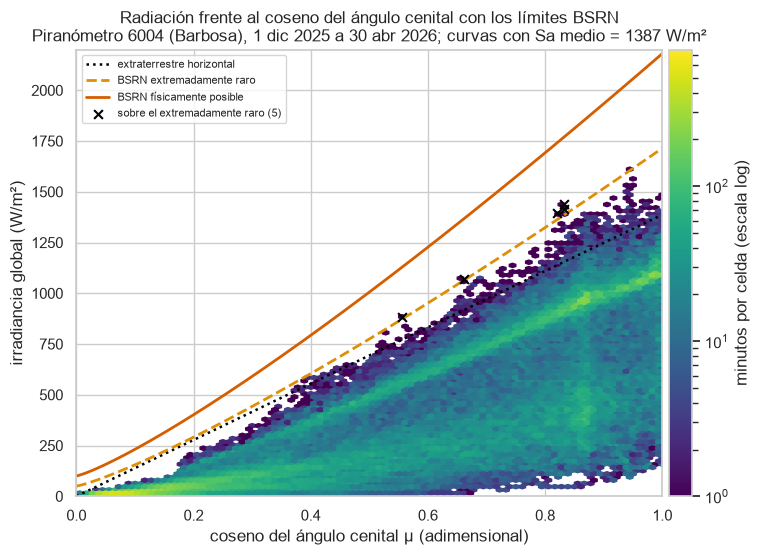

In [25]:
arr = d[sol_arriba & r.notna()]
mu = np.linspace(0, 1, 200)
sa = d["sa"].mean()
fig, ax = plt.subplots(figsize=(9, 5.8))
hb = ax.hexbin(arr["cos_z"], arr["radiacion"], gridsize=90, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, pad=0.01).set_label("minutos por celda (escala log)")
ax.plot(mu, sa * mu, color="black", ls=":", lw=1.8, label="extraterrestre horizontal")
ax.plot(mu, sa * 1.2 * mu ** 1.2 + 50, color=COL[1], ls="--", lw=2, label="BSRN extremadamente raro")
ax.plot(mu, sa * 1.5 * mu ** 1.2 + 100, color=COL[3], ls="-", lw=2, label="BSRN físicamente posible")
ext = d[r > raro]
ax.scatter(ext["cos_z"], ext["radiacion"], marker="x", s=40, color="black", zorder=3, label=f"sobre el extremadamente raro ({len(ext)})")
ax.set(xlim=(0, 1), ylim=(0, 2200), xlabel="coseno del ángulo cenital μ (adimensional)", ylabel="irradiancia global (W/m²)",
       title=f"Radiación frente al coseno del ángulo cenital con los límites BSRN\n{SUB}; curvas con Sa medio = {sa:.0f} W/m²")
ax.legend(loc="upper left", fontsize=8)
guardar(fig, "bsrn_cosz")
plt.show()

De 105 603 minutos con el sol arriba, 612 superan la extraterrestre horizontal, 5 superan el límite
"extremadamente raro" de BSRN y ninguno el "físicamente posible". Tampoco hay valores bajo -2 W/m², pero eso no habla bien
del sensor: no hay negativos, probablemente porque se recortan (inferido, ver la noche, abajo). Los 5 minutos extremadamente raros son del 1 y 4
dic y del 29 ene, todos con 1583 en SIATA y bandera 3 en el control propio, y el que más se pasa lo hace por 40 W/m² (4
dic, 10:39). La nube de puntos queda bajo la extraterrestre, con una franja de cielo despejado arriba y una de cielo
cubierto abajo. Sobre la cita: el mínimo de -4 W/m² y el máximo físicamente posible están en Long y Shi (2008) y en Long y
Dutton (BSRN V2.0); el máximo extremadamente raro de la global (Sa·1,2·μ^1,2 + 50) está en Long y Dutton.

Los minutos sobre la extraterrestre, ¿son errores o realce por nubes? El realce ocurre con cielo parcialmente
nublado: el sol directo llega entre nubes y se suma la luz que reflejan sus bordes. Long y Shi (2008) lo describen como
excursiones de pocos minutos sobre el valor de cielo despejado. Si es eso, los episodios deben ser cortos y con nubes
alrededor (kt bajo en la media hora previa o siguiente). Se toman con el sol a más de 5°.

In [26]:
sobre5 = (r > d["et"]) & (d["elevacion"] > 5)
bl = (sobre5 != sobre5.shift()).cumsum()
ge = d.index.to_series()[sobre5].groupby(bl[sobre5])
ep = pd.DataFrame({"inicio": ge.first(), "fin": ge.last(), "minutos": ge.size(),
                   "rad_max": r[sobre5].groupby(bl[sobre5]).max(),
                   "cociente_max": (r / d["et"])[sobre5].groupby(bl[sobre5]).max()}).reset_index(drop=True)
ep["kt_min_vecindad"] = [kt.loc[i - pd.Timedelta("30min"): f + pd.Timedelta("30min")].min() for i, f in zip(ep["inicio"], ep["fin"])]
print(f"minutos sobre la extraterrestre con el sol arriba: {int(sobre_et.sum())}; con el sol entre 0 y 5°: "
      f"{int((sobre_et & ~sobre5).sum())}")
print(f"episodios con el sol a más de 5°: {len(ep)} en {ep['inicio'].dt.normalize().nunique()} días; "
      f"{int(ep['minutos'].sum())} minutos")
print("duración (min):", ep["minutos"].describe()[["50%", "75%", "max"]].to_dict(), "| p90:", ep["minutos"].quantile(0.9))
print("radiación / extraterrestre en el pico del episodio:", ep["cociente_max"].quantile([0.5, 0.9, 1]).round(3).to_dict())
print(f"episodios con kt < 0,6 en la media hora antes o después: {(ep['kt_min_vecindad'] < 0.6).mean():.0%}; "
      f"kt mínimo mediano en esa vecindad: {ep['kt_min_vecindad'].median():.2f}")
print(f"máximo del periodo: {r.max():.2f} W/m² el {r.idxmax()} (extraterrestre {d.at[r.idxmax(), 'et']:.0f}, "
      f"límite raro {raro[r.idxmax()]:.0f}, Sa {d.at[r.idxmax(), 'sa']:.0f})")
print(f"minutos sobre 1498 W/m² (máximo histórico de la ficha, 26 abr 2019): {int((r > 1498).sum())}")
ep.sort_values("minutos", ascending=False).head(5)

minutos sobre la extraterrestre con el sol arriba: 612; con el sol entre 0 y 5°: 75
episodios con el sol a más de 5°: 238 en 68 días; 537 minutos
duración (min): {'50%': 2.0, '75%': 3.0, 'max': 13.0} | p90: 4.0
radiación / extraterrestre en el pico del episodio: {0.5: 1.04, 0.9: 1.112, 1.0: 1.234}
episodios con kt < 0,6 en la media hora antes o después: 100%; kt mínimo mediano en esa vecindad: 0.33
máximo del periodo: 1611.03 W/m² el 2026-02-24 12:53:00 (extraterrestre 1317, límite raro 1614, Sa 1390)
minutos sobre 1498 W/m² (máximo histórico de la ficha, 26 abr 2019): 7


,inicio,fin,minutos,rad_max,cociente_max,kt_min_vecindad
17,2025-12-04 11:41:00,2025-12-04 11:53:00,13,1390.47,1.129206,0.464315
65,2026-01-13 14:39:00,2026-01-13 14:51:00,13,1082.60,1.119948,0.216616
53,2026-01-06 11:29:00,2026-01-06 11:40:00,12,1385.92,1.140000,0.327314
107,2026-02-03 11:41:00,2026-02-03 11:49:00,9,1362.17,1.065484,0.343667
114,2026-02-04 08:00:00,2026-02-04 08:07:00,8,582.22,1.043715,0.272584


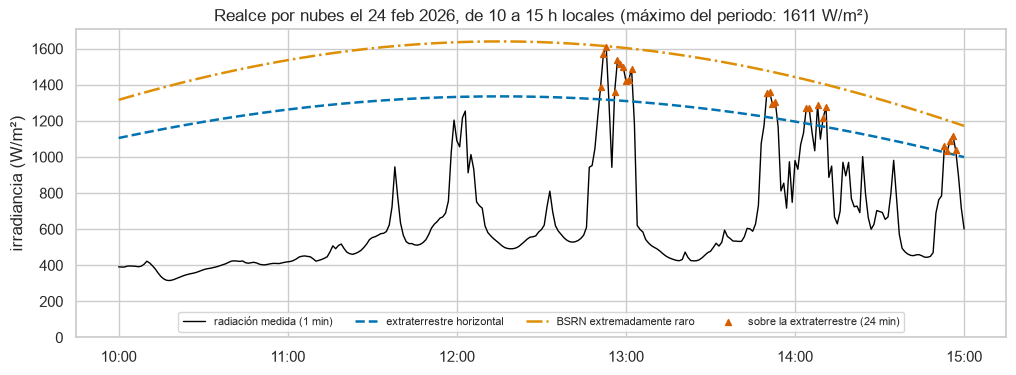

In [27]:
pico = r.idxmax()
v_ej = d.loc[pico.normalize() + pd.Timedelta("10h"): pico.normalize() + pd.Timedelta("15h")]
marcas = v_ej[v_ej["radiacion"] > v_ej["et"]]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(v_ej.index, v_ej["radiacion"], color="black", lw=1, label="radiación medida (1 min)")
ax.plot(v_ej.index, v_ej["et"], color=COL[0], ls="--", lw=1.8, label="extraterrestre horizontal")
ax.plot(v_ej.index, raro.loc[v_ej.index], color=COL[1], ls="-.", lw=1.8, label="BSRN extremadamente raro")
ax.scatter(marcas.index, marcas["radiacion"], color=COL[3], marker="^", s=18, zorder=3, label=f"sobre la extraterrestre ({len(marcas)} min)")
ax.set(ylabel="irradiancia (W/m²)", ylim=(0, None), title=f"Realce por nubes el {fecha(pico)}, de 10 a 15 h locales (máximo del periodo: {r.max():.0f} W/m²)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(fontsize=8, loc="lower center", ncol=4)
plt.show()

Los minutos sobre la extraterrestre se comportan como realce por nubes, un evento físico real. Con el sol a
más de 5° hay 238 episodios en 68 días (537 minutos): la mediana dura 2 min, el 90 % dura 4 min o menos y el más largo
13 min. En el pico del episodio la radiación supera la extraterrestre en una mediana del 4 % y como máximo en un 23 %.
Todos los episodios tienen nubes en la media hora vecina (kt < 0,6 en el 100 %; el mínimo mediano es 0,33). El máximo del
periodo, 1611,03 W/m² el 24 feb a las 12:53, supera la constante solar corregida de ese día (1390 W/m²) y el máximo
histórico de la ficha (1498 W/m², 26 abr 2019; 7 minutos lo superan en este periodo), pero queda bajo el límite
extremadamente raro de ese minuto (1614 W/m²) y ocurre entre caídas a unos 500 W/m² (gráfico): es sol entre nubes. Long
y Shi (2008) describen estas excursiones de pocos minutos con cielo parcialmente nublado, y valores sobre 1400 W/m² en
sitios tropicales. Por eso no se borran: se conservan y solo se marca como sospechoso lo que pasa el límite
extremadamente raro.

¿Qué pasa de noche? Un piranómetro de termopila suele dar valores levemente negativos de noche (el offset
térmico que la ficha describe con el código 1581).

In [28]:
print("valores negativos en todo el periodo:", int((r < 0).sum()))
print("radiación > 0 con el sol a más de 3° bajo el horizonte:", int(((d["elevacion"] < -3) & (r > 0)).sum()))
crep = d["elevacion"].between(-3, 0) & (r > 0)
print(f"radiación > 0 con el sol entre 0 y 3° bajo el horizonte (crepúsculo): {int(crep.sum())} minutos, máximo {r[crep].max():.2f} W/m²")
print("minutos con 1581:", int((d["calidad"] == 1581).sum()))

valores negativos en todo el periodo: 0
radiación > 0 con el sol a más de 3° bajo el horizonte: 0
radiación > 0 con el sol entre 0 y 3° bajo el horizonte (crepúsculo): 550 minutos, máximo 16.00 W/m²
minutos con 1581: 0


No hay un solo valor negativo en todo el periodo, ninguna radiación con el sol a más de 3° bajo el horizonte y
ningún 1581. Lo único positivo con el sol bajo el horizonte son 550 minutos de crepúsculo (máximo 16 W/m²), que es luz
real. Una noche tan perfecta no es lo normal en un piranómetro de termopila; la propia ficha define el 1581 para los
negativos de noche. Lo más probable es que el sistema recorte a cero antes de publicar (inferido). El costo es que se
pierde la señal para vigilar y corregir el offset térmico, y que el mínimo de BSRN (-4 W/m²) nunca puede fallar.

¿Hay ceros exactos de día, cuando el cielo más oscuro todavía deja pasar luz difusa?

,inicio,fin,minutos
0,2026-02-14 15:48:00,2026-02-14 16:14:00,27


elevación del sol durante el bloque: 27.7° a 33.8°; calidad SIATA: [1.]; bandera propia: [1]
ventana de la prueba de persistencia del control propio (min, cambio mínimo): (30, 0.01)
tramo con radiación < 5 W/m² y el sol a más de 10° que contiene los ceros: 15:43 a 17:28 (106 min)
días con algún minuto < 5 W/m² y el sol a más de 20°: ['14 feb 2026', '27 abr 2026']


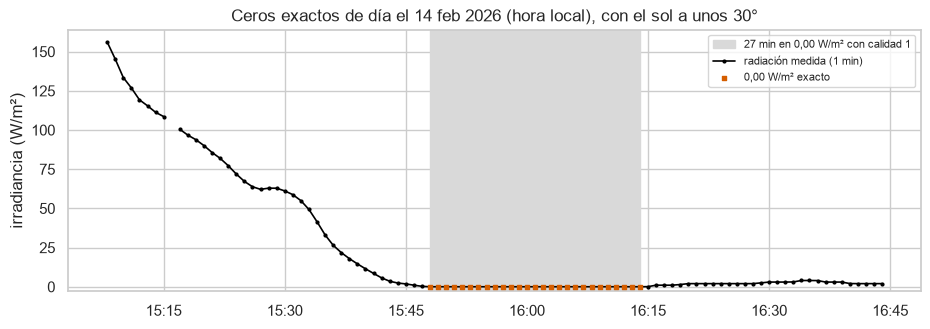

In [29]:
cero_dia = (r == 0) & (d["elevacion"] > 10)
bz = (cero_dia != cero_dia.shift()).cumsum()
gz = d.index.to_series()[cero_dia].groupby(bz[cero_dia])
bloques_cero = pd.DataFrame({"inicio": gz.first(), "fin": gz.last(), "minutos": gz.size()}).reset_index(drop=True)
display(bloques_cero)
z = bloques_cero.loc[bloques_cero["minutos"].idxmax()]
vz = d.loc[z["inicio"] - pd.Timedelta("40min"): z["fin"] + pd.Timedelta("30min")]
print(f"elevación del sol durante el bloque: {d.loc[z['inicio']:z['fin'], 'elevacion'].min():.1f}° a "
      f"{d.loc[z['inicio']:z['fin'], 'elevacion'].max():.1f}°; calidad SIATA: {d.loc[z['inicio']:z['fin'], 'calidad'].unique()}; "
      f"bandera propia: {d.loc[z['inicio']:z['fin'], 'b'].unique()}")
print("ventana de la prueba de persistencia del control propio (min, cambio mínimo):", Q.UMBRALES["persistencia"]["radiacion"])
b5 = (r < 5) & (d["elevacion"] > 10)
bb = (b5 != b5.shift()).cumsum()
bloque_z = d.index[(bb == bb.loc[z["inicio"]]).to_numpy()]
print(f"tramo con radiación < 5 W/m² y el sol a más de 10° que contiene los ceros: {bloque_z[0]:%H:%M} a {bloque_z[-1]:%H:%M} ({len(bloque_z)} min)")
print("días con algún minuto < 5 W/m² y el sol a más de 20°:", sorted({fecha(t) for t in d.index[((r < 5) & (d['elevacion'] > 20)).to_numpy()]}))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axvspan(z["inicio"], z["fin"], color="0.85", label=f"{int(z['minutos'])} min en 0,00 W/m² con calidad 1")
ax.plot(vz.index, vz["radiacion"], color="black", lw=1.2, marker="o", ms=2, label="radiación medida (1 min)")
ceros = vz[(vz["radiacion"] == 0) & (vz["elevacion"] > 10)]
ax.scatter(ceros.index, ceros["radiacion"], color=COL[3], marker="s", s=12, zorder=3, label="0,00 W/m² exacto")
ax.set(ylabel="irradiancia (W/m²)", ylim=(-3, None), title=f"Ceros exactos de día el {fecha(z['inicio'])} (hora local), con el sol a unos 30°")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(fontsize=8)
plt.show()

El 14 feb, de 15:48 a 16:14, la radiación vale 0,00 W/m² durante 27 minutos seguidos con el sol entre 27,7°
y 33,8°, con calidad 1 en SIATA y bandera 1 en el control propio. Antes cae de forma suave desde unos 150 W/m² y después
se queda entre 1 y 3 W/m²: en total son 106 minutos (15:43 a 17:28) bajo 5 W/m² con el sol a más de 10°. Con el sol a más
de 20°, valores bajo 5 W/m² solo aparecen ese día y el 27 abr. Con el sol a 30° hasta una tormenta muy oscura deja pasar
algo de luz difusa, así que se trata como sospechoso: puede ser una tormenta excepcional o el sensor tapado (agua,
suciedad, un objeto), y en estos datos no hay otra estación de radiación para decidirlo. El control propio no lo marcó
porque su prueba de persistencia pide 30 minutos y el bloque de ceros dura 27. Es un caso para una regla nueva (A6).

¿Qué tan de acuerdo están la columna `calidad` y el control propio del repositorio? Y ¿qué marcó el control
propio?

In [30]:
display(pd.crosstab(d["calidad"].fillna(-1).astype(int).replace(-1, "sin dato"), d["b"], rownames=["calidad SIATA"],
                    colnames=["bandera propia (1 bueno, 3 sospechoso, 9 faltante)"]))
ind = pd.read_csv(datos.RAIZ / "parte2" / "resultados" / "indicadores_periodo.csv", dtype={"codigo": str}).query("codigo == '6004'")
display(ind[["completitud", "validos", "kappa", "falsos_confiables", "dudosos_que_pasan"]].round(4))
f6004 = pd.read_parquet(datos.DIR_SALIDAS / "fallas.parquet").query("codigo == '6004' and prueba != 'hueco'")
print("pruebas del control propio que fallaron:", f6004.groupby("prueba").size().to_dict())
s = r.diff().where(d.index.to_series().diff() == pd.Timedelta("1min")).abs()
print(f"saltos > {Q.UMBRALES['salto']['radiacion']} W/m² entre minutos: {int((s > Q.UMBRALES['salto']['radiacion']).sum())}; "
      f"salto máximo {s.max():.0f} W/m² el {s.idxmax()}; horas locales: {sorted(set(s[s > 800].index.hour))}")

"bandera propia (1 bueno, 3 sospechoso, 9 faltante)",1,3,9
calidad SIATA,,,
1,213063,30,0
1582,977,0,0
1583,746,7,0
sin dato,0,0,2617


,completitud,validos,kappa,falsos_confiables,dudosos_que_pasan
9,0.988,0.9998,0.0076,0.0001,0.996


pruebas del control propio que fallaron: {'radiacion_extrema': 5, 'salto': 32}
saltos > 800 W/m² entre minutos: 16; salto máximo 892 W/m² el 2026-02-19 12:11:00; horas locales: [11, 12, 13]


La columna `calidad` y el control propio casi no coinciden (kappa de 0,008), y no porque uno marque más que el
otro: marcan cosas distintas. SIATA marca 1730 minutos (977 con 1582 y 753 con 1583) y el control propio 37; solo 7
coinciden. Del lado de SIATA, los 1582 son crepúsculos reales y casi ningún 1583 pasa el límite extremadamente raro. Del
lado propio, 32 de las 37 marcas son de la prueba de salto: 16 cambios de más de 800 W/m² entre minutos, todos entre las
11 y las 13 h, con un máximo de 892 W/m² (19 feb, 12:11). Con los dos modos de kt (0,24 y 0,79) y una extraterrestre de
unos 1300 W/m² al mediodía, pasar de nublado a despejado ya es un cambio de unos 700 W/m², y con realce pasa de 800: son
bordes de nubes, falsos positivos del umbral fijo. Ninguno de los dos controles detecta los ceros del 14 feb.

¿El horizonte de montañas se nota en los datos? Se mira el percentil 95 de kt (los minutos más claros) por
banda de elevación solar, en la mañana y en la tarde.

In [31]:
bajo = d[(d["elevacion"] > 0) & (d["elevacion"] < 20) & r.notna()]
tabla_h = ((bajo["radiacion"] / bajo["et"])
           .groupby([(bajo["elevacion"] // 2 * 2).astype(int).rename("elevación (°, banda de 2)"),
                     np.where(bajo.index.hour < 12, "mañana", "tarde")]).quantile(0.95).unstack().round(2))
tabla_h.T

"elevación (°, banda de 2)",0,2,4,6,8,10,12,14,16,18
mañana,0.76,0.30,0.33,0.35,0.36,0.49,0.56,0.56,0.58,0.64
tarde,0.60,0.29,0.29,0.30,0.32,0.50,0.57,0.59,0.62,0.64


Con el sol entre 2° y 10° el percentil 95 de kt no pasa de 0,36, ni en la mañana ni en la tarde; en la banda
de 10° a 12° salta a 0,49 y 0,50 y después sigue subiendo poco a poco. Un descenso suave con la elevación es normal (hay
más atmósfera que atravesar), pero un salto de 0,13 a 0,18 entre dos bandas vecinas sugiere que las montañas del valle
tapan el sol directo hasta unos 10° de elevación, mañana y tarde, y que por debajo el sensor solo ve luz difusa (inferido;
el perfil de la ficha muestra terreno más alto a los dos lados, pero no trae el horizonte). Esto explica parte de los
amaneceres y atardeceres bajos y respalda que la prueba de persistencia del control propio solo se aplique con el sol a
más de 10°.

## A6. Hallazgos priorizados

La tabla se arma con las cifras calculadas arriba. Prioridad alta: cambia el uso del dato o de la bandera; media: afecta
cálculos concretos; baja: hay que documentarlo.

In [32]:
n_1582_regla = int((regla_local & es1582).sum())
n_desacuerdo = int((regla_local != es1582).sum())
dom = evento.loc["domingo"]
hallazgos = pd.DataFrame([
    {"prioridad": "alta",
     "problema": "El reloj del archivo está en UTC y solo lo dice la guía de la red (P-GAA-SIATA-111), no la ficha ni el archivo",
     "evidencia": (f"Leído como hora local, {miles(conteo['archivo en hora local'])} registros superan la radiación "
                   f"extraterrestre; leído como UTC, {miles(conteo['archivo en UTC'])}. El barrido de desfases tiene el "
                   f"mínimo en {barrido.idxmin()} min. El pico medio cae a las {perfil['radiación medida'].idxmax()} h del archivo"),
     "impacto": "Todo cruce con las otras estaciones (en hora local) y todo agregado diario queda corrido 5 h",
     "recomendacion": "Declarar la zona horaria en los metadatos y en la marca (ISO 8601 con desfase); convertir en la ingesta, como hace regularizar, con una prueba"},
    {"prioridad": "alta",
     "problema": "El código 1582 usa una ventana fija de reloj (18:00 a 06:00 locales), no la posición del sol",
     "evidencia": (f"La regla 'radiación > 0 entre 18:00 y 06:00 locales' reproduce los {n_1582_regla} minutos con 1582 "
                   f"con {n_desacuerdo} desacuerdos; el {(q82['elevacion'] > 0).mean():.0%} tiene el sol sobre el horizonte"),
     "impacto": "Marca como dudosos datos reales del amanecer y del atardecer; el error cambia con la hora de la puesta",
     "recomendacion": "Definir la noche por la elevación solar (sol a más de 3° bajo el horizonte), como el control propio"},
    {"prioridad": "alta",
     "problema": "El código 1583 no equivale a superar la radiación extraterrestre",
     "evidencia": (f"{int((q83['radiacion'] <= q83['et']).sum())} de {len(q83)} minutos con 1583 están por debajo de la "
                   f"extraterrestre, sobre todo a las 17 h; {len(p1)} minutos sobre la extraterrestre salen con 1. "
                   f"Kappa entre calidad y el control propio: {ind['kappa'].iloc[0]:.3f}"),
     "impacto": "Filtrar por calidad = 1 deja pasar minutos sobre la extraterrestre y quita minutos válidos del atardecer",
     "recomendacion": "Publicar el modelo de radiación teórica y su versión; contrastar con la extraterrestre y los límites BSRN"},
    {"prioridad": "media",
     "problema": "Los valores negativos se recortan a cero antes de publicar (inferido)",
     "evidencia": (f"0 negativos en {miles(len(crudo))} registros y 0 minutos con 1581; con el sol a más de 3° bajo el "
                   f"horizonte la radiación es 0,00 en el {(r[noche].dropna() == 0).mean():.0%} de los minutos"),
     "impacto": "Se pierde el offset térmico del sensor: no se puede vigilar ni corregir, y el mínimo de BSRN no se puede probar",
     "recomendacion": "Guardar la señal sin recortar en el nivel crudo; si se recorta, hacerlo solo en el producto y documentarlo"},
    {"prioridad": "media",
     "problema": "Ceros exactos de día con calidad 1",
     "evidencia": (f"{int(z['minutos'])} min seguidos en 0,00 W/m² el {fecha(z['inicio'])} con el sol a "
                   f"{d.loc[z['inicio']:z['fin'], 'elevacion'].min():.0f}° a {d.loc[z['inicio']:z['fin'], 'elevacion'].max():.0f}°; "
                   f"ni SIATA ni el control propio (ventana de persistencia de {Q.UMBRALES['persistencia']['radiacion'][0]} min) lo marcan"),
     "impacto": "Un sensor tapado o desconectado pasaría como dato confiable si dura menos de media hora",
     "recomendacion": "Regla nueva: cero exacto con el sol a más de 10° durante 10 min o más pasa a sospechoso y a revisión humana"},
    {"prioridad": "media",
     "problema": "Huecos: uno largo, un evento semanal y una racha de cortes cortos en enero",
     "evidencia": (f"{len(huecos)} huecos, {miles(int(falta.sum()))} min ({1 - d['presente'].mean():.1%}); el del "
                   f"{fecha(largo['inicio'])} dura {miles(int(largo['minutos']))} min ({largo['minutos'] / falta.sum():.0%} de lo que falta); "
                   f"{int(dom['dias_con_evento'])} de {int(dom['dias'])} domingos pierden o retrasan el registro de las 22:01; "
                   f"{len(ene)} cortes de 1 o 2 min del 2 al 20 de enero"),
     "impacto": f"{int(diario['E'].isna().sum())} de {len(diario)} días quedan sin energía diaria válida",
     "recomendacion": "Alerta cuando falten más de 30 min de día; revisar la tarea programada del domingo a las 22 h y la transmisión de enero"},
    {"prioridad": "baja",
     "problema": "Minutos sobre la extraterrestre por realce de nubes (evento físico real)",
     "evidencia": (f"{len(ep)} episodios con el sol a más de 5°: mediana {ep['minutos'].median():.0f} min, máximo "
                   f"{int(ep['minutos'].max())}; el {(ep['kt_min_vecindad'] < 0.6).mean():.0%} con nubes en la media hora vecina. "
                   f"Máximo {r.max():.0f} W/m²; {int(cuenta['sobre el límite extremadamente raro'])} minutos sobre el límite "
                   f"extremadamente raro de BSRN y {int(cuenta['sobre el límite físicamente posible'])} sobre el físicamente posible"),
     "impacto": "Borrar todo lo que supera la extraterrestre elimina extremos reales y sesga la energía hacia abajo",
     "recomendacion": "Conservarlos; marcar sospechoso solo sobre el límite extremadamente raro y revisar con una estación vecina"},
    {"prioridad": "baja",
     "problema": "Marcas de tiempo con segundos distintos de cero",
     "evidencia": f"{len(fuera)} marcas; {int((fuera['dia_local'] == 'domingo').sum())} son domingos hacia las 22:0x locales; una cae en un minuto ya ocupado",
     "impacto": "Un join exacto por fecha_hora pierde esos registros",
     "recomendacion": "Llevar al minuto (floor) y conservar el primero, documentado; es lo que hace regularizar"},
    {"prioridad": "media",
     "problema": "Metadatos de la estación desactualizados o incompletos",
     "evidencia": (f"La ficha (actualizada el 2024-09-18) dice 'Estado: Inactiva' y el periodo tiene "
                   f"{d['presente'].mean():.1%} de completitud; no declara zona horaria (la guía de la red sí); lista temperatura, que el archivo "
                   f"no trae; su latitud es 6,406612 y la del código es {EST['lat']}"),
     "impacto": "Un usuario puede descartar la estación o cruzarla mal; el catálogo pierde confianza",
     "recomendacion": "Mantener el estado y la zona horaria en la ficha (metadatos WIGOS e ISO 19115) y unificar coordenadas"},
    {"prioridad": "baja",
     "problema": "El umbral fijo de salto del control propio marca bordes de nubes",
     "evidencia": (f"{int((s > Q.UMBRALES['salto']['radiacion']).sum())} saltos de más de {Q.UMBRALES['salto']['radiacion']} W/m² "
                   f"entre minutos, todos de 11 a 13 h; el mayor es de {s.max():.0f} W/m²"),
     "impacto": f"{int(f6004['prueba'].eq('salto').sum())} minutos que parecen bordes de nubes reales quedan como sospechosos",
     "recomendacion": "Hacer el umbral relativo a la extraterrestre del minuto o combinarlo con la persistencia del valor nuevo"},
], index=range(1, 11))
orden = {"alta": 0, "media": 1, "baja": 2}
hallazgos = hallazgos.sort_values("prioridad", key=lambda s: s.map(orden), kind="stable")
hallazgos.index = range(1, len(hallazgos) + 1)
# texto para personas: decimales con coma y espacio antes de %
hallazgos = hallazgos.replace({r"(\d)\.(\d)": r"\1,\2", r"(\d)%": r"\1 %"}, regex=True)
with pd.option_context("display.max_colwidth", None):
    display(hallazgos)

,prioridad,problema,evidencia,impacto,recomendacion
1,alta,"El reloj del archivo está en UTC y solo lo dice la guía de la red (P-GAA-SIATA-111), no la ficha ni el archivo","Leído como hora local, 63 862 registros superan la radiación extraterrestre; leído como UTC, 1 163. El barrido de desfases tiene el mínimo en 299 min. El pico medio cae a las 17 h del archivo",Todo cruce con las otras estaciones (en hora local) y todo agregado diario queda corrido 5 h,"Declarar la zona horaria en los metadatos y en la marca (ISO 8601 con desfase); convertir en la ingesta, como hace regularizar, con una prueba"
2,alta,"El código 1582 usa una ventana fija de reloj (18:00 a 06:00 locales), no la posición del sol",La regla 'radiación > 0 entre 18:00 y 06:00 locales' reproduce los 977 minutos con 1582 con 0 desacuerdos; el 79 % tiene el sol sobre el horizonte,Marca como dudosos datos reales del amanecer y del atardecer; el error cambia con la hora de la puesta,"Definir la noche por la elevación solar (sol a más de 3° bajo el horizonte), como el control propio"
3,alta,El código 1583 no equivale a superar la radiación extraterrestre,"308 de 753 minutos con 1583 están por debajo de la extraterrestre, sobre todo a las 17 h; 138 minutos sobre la extraterrestre salen con 1. Kappa entre calidad y el control propio: 0,008",Filtrar por calidad = 1 deja pasar minutos sobre la extraterrestre y quita minutos válidos del atardecer,Publicar el modelo de radiación teórica y su versión; contrastar con la extraterrestre y los límites BSRN
4,media,Los valores negativos se recortan a cero antes de publicar (inferido),"0 negativos en 214 824 registros y 0 minutos con 1581; con el sol a más de 3° bajo el horizonte la radiación es 0,00 en el 100 % de los minutos","Se pierde el offset térmico del sensor: no se puede vigilar ni corregir, y el mínimo de BSRN no se puede probar","Guardar la señal sin recortar en el nivel crudo; si se recorta, hacerlo solo en el producto y documentarlo"
5,media,Ceros exactos de día con calidad 1,"27 min seguidos en 0,00 W/m² el 14 feb 2026 con el sol a 28° a 34°; ni SIATA ni el control propio (ventana de persistencia de 30 min) lo marcan",Un sensor tapado o desconectado pasaría como dato confiable si dura menos de media hora,Regla nueva: cero exacto con el sol a más de 10° durante 10 min o más pasa a sospechoso y a revisión humana
6,media,"Huecos: uno largo, un evento semanal y una racha de cortes cortos en enero","207 huecos, 2 617 min (1,2 %); el del 8 abr 2026 dura 1 752 min (67 % de lo que falta); 17 de 22 domingos pierden o retrasan el registro de las 22:01; 104 cortes de 1 o 2 min del 2 al 20 de enero",17 de 151 días quedan sin energía diaria válida,Alerta cuando falten más de 30 min de día; revisar la tarea programada del domingo a las 22 h y la transmisión de enero
7,media,Metadatos de la estación desactualizados o incompletos,"La ficha (actualizada el 2024-09-18) dice 'Estado: Inactiva' y el periodo tiene 98,8 % de completitud; no declara zona horaria (la guía de la red sí); lista temperatura, que el archivo no trae; su latitud es 6,406612 y la del código es 6,406712",Un usuario puede descartar la estación o cruzarla mal; el catálogo pierde confianza,Mantener el estado y la zona horaria en la ficha (metadatos WIGOS e ISO 19115) y unificar coordenadas
8,baja,Minutos sobre la extraterrestre por realce de nubes (evento físico real),"238 episodios con el sol a más de 5°: mediana 2 min, máximo 13; el 100 % con nubes en la media hora vecina. Máximo 1611 W/m²; 5 minutos sobre el límite extremadamente raro de BSRN y 0 sobre el físicamente posible",Borrar todo lo que supera la extraterrestre elimina extremos reales y sesga la energía hacia abajo,Conservarlos; marcar sospechoso solo sobre el límite extremadamente raro y revisar con una estación vecina
9,baja,Marcas de tiempo con segundos distintos de cero,15 marcas; 12 son domingos hacia las 22:0x locales; una cae en un minuto ya ocupado,Un join exacto por fecha_hora pierde esos registros,

Figuras guardadas para el informe en `parte2/figuras/`: `03_reloj_utc.png` (zona horaria), `03_codigos_calidad.png`
(1582 y 1583 frente al sol), `03_bsrn_cosz.png` (límites BSRN) y `03_energia_diaria.png` (energía y KT diarios).

Lo que este notebook no resuelve: en los datos no hay otra estación de radiación para validar contra una vecina los ceros
del 14 feb ni el realce por nubes, y el modelo de radiación teórica de SIATA (código 1583) no está publicado.